# 12 — Atomics on every path of the H100: shared memory, distributed shared memory, L2 near and far, HBM, host memory

**Goal.** Measure, on one H100 NVL at a locked 1635 MHz SM clock, what an atomic memory operation costs on each path it can take:
- the CTA's own shared memory (`atom/red.shared::cta`);
- the own shared memory addressed through the cluster window (`.shared::cluster` with the CTA's own rank);
- a peer CTA's shared memory in the same cluster (distributed shared memory, DSMEM);
- global memory with the line in L2, homed in the issuer's L2 partition ("near") or in the other one ("far");
- global memory with the line in HBM only (an L2 miss);
- pinned host memory, mapped into the GPU's address space.

For every path: the dependent latency of each operation and memory-ordering semantics, the throughput of one SM and of the whole GPU, with and without contention on one word, one bank or a few hot lines. Plus the DSMEM signalling primitives built on remote writes: `red.async` and `st.async` with hardware completion, how long a hand-off between two SMs takes with each primitive, and whether the width of a remote store changes its cost.

**Why it matters.** Atomics are how GPU programs combine partial results (histograms, reductions, counters, locks, work queues) and how CTAs signal each other. On this chip the same instruction can execute in four different places (the issuing SM, another SM of the GPC, one of two L2 partitions, or the host), each with its own latency, throughput and contention behaviour. A model of a GPU with a different memory hierarchy needs each of these separately, not one "atomic latency".

## 2. Background

**`atom` and `red`.** PTX has two forms of every atomic read-modify-write:

```
atom{.sem}{.scope}.space.op.type  d, [a], b;      // returns the old value d (cas: atom.cas d, [a], compare, new)
red{.sem}{.scope}.space.op.type   [a], b;         // no return value: the issuing thread does not wait for it
```

- Operations measured here: integer `add.u32`, `add.u64`, `inc.u32`, `min.s32`, `max.u32`, `and.b32`, `exch.b32`, `cas.b32`, `cas.b64`; floating-point `add.f32`, `add.f64`, `add.noftz.f16x2`, `add.noftz.bf16x2` (two 16-bit values per 32-bit word); for global memory also the vector forms `add.v2/v4.f32` and `add.noftz.v2/v4.f16x2`.
- **Semantics and scope.** The default is `.relaxed` at `.gpu` scope: the operation is atomic, but it orders nothing else. `.acq_rel` (`atom`) or `.release` (`red`) also orders the thread's earlier and later memory accesses, at the named scope: `.cta`, `.cluster` (the CTAs of a cluster), `.gpu` or `.sys` (the GPU and the host).
- **Where the operation executes.**
  - `.shared::cta`: in the shared-memory unit of the issuing SM (SASS `ATOMS`).
  - `.shared::cluster`: a generic atomic (`ATOM.E`) on an address of the cluster's shared-memory window. If the address belongs to the own CTA, it is served by the own SM; if it belongs to a peer CTA, the request crosses the GPC's SM-to-SM network and executes in the peer SM's shared memory, and the old value travels back.
  - `.global`: in the L2 (`ATOMG` with return, `REDG` without). The L2 of this GPU is split into two partitions; every 128-B line has an address-determined **home** partition. A *load* from the other partition leaves a copy of the line in the reader's partition, so repeated loads are served near. Section 4.2 measures whether atomics behave like that.
  - Host memory (`cudaHostAlloc`, mapped): over PCIe.
- **Compare-and-swap loops.** Not every operation exists in hardware for every space. The compiler then emits a loop that reads the word, computes the new value and retries `cas` until no other thread changed the word in between. Table 3 lists the SASS each operation becomes here.

**`red.async` and `st.async`.** Two remote writes into a peer CTA's shared memory that signal their own completion:

```
red.async.relaxed.cluster.shared::cluster.mbarrier::complete_tx::bytes.add.u32  [peer + off], v, [peer_mbar];
st.async.shared::cluster.mbarrier::complete_tx::bytes.v4.b32                    [peer + off], {a,b,c,d}, [peer_mbar];
```

- The receiving CTA arms an **mbarrier** (a 64-bit synchronisation object in its own shared memory) with the number of bytes it expects (`mbarrier.arrive.expect_tx`).
- Every arriving write counts its bytes down, and the receiver waits until the count reaches zero (`mbarrier.try_wait`). The receiver therefore observes the arrival of the data without polling the data itself, and the sender needs no memory fence.

**Hand-off (store visibility).** For two CTAs that take turns, the time from one CTA's signal to the other's observation sets the speed of every producer–consumer protocol. A signal is a plain remote store, a release store, a remote `red` or `atom` on a flag, or an `st.async` / `red.async` with the mbarrier completion above. The receiver polls its own shared memory or waits on its mbarrier.

## 3. Experimental setup

**Device and configuration.** Device and clock data are in the table below, from the CSV columns of every run: H100 NVL, 132 SMs in 8 GPCs (12, 16, 16, 16, 18, 18, 18, 18 SMs), SM clock locked at 1635 MHz, HBM3 at 2619 MHz, power limit 400 W, ECC on, CUDA 12.9 (`sm_90a`, `-O3`). Every launch is followed by a clock sample (NVML). A launch with a throttle reason, an SM clock below the lock, or CTAs on other SMs than intended is discarded and repeated; the counts are in the table below.

**L2 partition of every SM (K0a).** The home partition of a line decides whether a global atomic is near or far, so it is measured on this card before anything else:
- Lines of a buffer are labelled by timing: written by SM 0, read once by SM 2, and the reverse. A line read near by SM 2 after SM 0 wrote it is homed in SM 2's partition.
- Then, for every SM, 64 lines of each home are written by an SM of their home partition and read once by that SM. Its partition is the home it reads fast.
- **Partition 0** (by definition the partition of SM 0) = GPCs {0, 5, 6, 7}; **partition 1** = GPCs {1, 2, 3, 4}; 66 SMs each, the same for every SM of a GPC.
- Each binary run labels its own 512 MiB buffer per 4 KiB page, because the home depends on the physical page. The first 16 MiB are also labelled per line, to check that every line of a 4 KiB page has the page's home.

**Dependent latency (K1).** One thread (lane 0 of a one-warp CTA) walks a chain in which each element holds the position of the next one. The atomic's returned value is the next address, so every operation waits for the previous one.
- **Identity operands.** Each operation uses an operand that leaves the element unchanged: `add` +0 in every format, `min.s32` with INT_MAX, `max.u32` with 0, `and.b32` with ~0. The same chain can therefore be walked again. Elements are stored as normal floating-point values (an f32 or f64 in [2, 4), two f16/bf16 halves in their normal range), so floating-point adds return them exactly. `inc.u32` and the `add +1` control add 1, which moves the next access one word further inside the same element. `exch.b32` writes the previous element's word, which reverses the chain. `cas` compares with 0, which never matches, so memory is unchanged (`cas_fail`). CAS that succeeds and `inc` are also timed on one fixed word ("same word", address dependent on the previous result).
- **Address cost.** Turning the returned value into the next address costs one integer multiply-add per hop (or one `LEA`); the f16x2 / bf16x2 encoding needs a few more instructions. The same-binary plain-load chain of the same format carries the same cost. Its value is shown next to every atomic.
- **`red` has no return value.** It is timed as `red` followed by a plain load of the same word, which returns the next position ("red+ld": the time until the issuing thread can read its own reduction).
- **Timing.** Each value is the slope between a 4096-hop and a 16 384-hop walk: (cycles(16 384) − cycles(4096)) / 12 288 SM cycles (`%clock64`), so the fixed cost of the timer and the loop cancels. Exceptions: host memory uses 256 / 1024 hops; HBM and the per-access histograms use one timed operation per sample (`%clock64` before, a timer read that waits for the returned value after; the timer cost is included).

**Placement and targets of K1.**
- **Shared memory** (T1, own smem through the window T2): one CTA per SM (200 KB of dynamic shared memory) on all 132 SMs at once. Each SM chases a random cycle over 128 KiB of its own shared memory; T2 runs as clusters of 2.
- **Peer CTA (DSMEM, T3).**
  - A single cluster of 2, 4 or 16 CTAs; the hardware places them on SMs 124/125, in GPC 0 from SM 0, and on GPC 1. Rank 0 chases every peer's chain in turn.
  - For the per-SM-pair view, full waves of clusters of 16, 8, 4 and 2; every rank chases every other rank in turn.
- **L2 near / far** (T4/T5): one warp pinned to the first SM of every GPC, on a chain over 8 MiB of lines homed in its own partition (near) or in the other one (far). Protocol per launch:
  - Clean the L2.
  - A warp on an SM of the lines' home partition writes the whole chain, so every line lives only at its home.
  - **Pass 1**: the chain is walked once.
  - **Pass 2**: the same lines again, without cleaning.
  - **Pass 2ld**: a plain `ld.global.cg` walk over the same lines, which shows whether the atomics left a near copy.
- **HBM** (T6): one walk of 131 072 operations per launch over a random cycle of all lines of 256 MiB, after cleaning the L2, so every operation misses. Near / far is the home of each line's page.
- **Host memory** (T7): 4096 lines of `cudaHostAlloc`'d memory, mapped; host-native atomics are not supported on this system (`cudaDevAttrHostNativeAtomicSupported` = 0), so the GPU performs them on the memory over PCIe.

**Throughput.**
- **Per SM (K2):** one CTA of 128–1024 threads (or one on every SM at once), each thread issuing 1, 2, 4 or 8 independent operations per step for 4096 steps (results of `atom` consumed after the step). Address patterns:
  - `coal`: 32 consecutive words per warp instruction; conflict-free in shared memory;
  - `sector` / `line`: one 32-B sector / one 128-B line per lane;
  - `bank`: shared memory only; the 32 lanes on different words of one bank;
  - `warp1`: the 32 lanes on one word;
  - `block1`: every thread of the CTA on one word.

  Targets: the 128 KiB of local, own-window and peer smem; 8 MiB of near / far lines (L2-resident after warm-up launches); a single pass over 256 MiB (HBM, cleaned L2 before every launch). Per-CTA cycles are taken between a CTA-wide barrier at the start and the end of the last operation; every thread fences at the end, so posted `red` / `st` are complete.
- **GPU-wide (K3):** 2 × 132 CTAs × 1024 threads, 4 operations per thread and step; cudaEvent time per launch, net of the 3.9 µs cudaEvent floor.
  - Footprint 1–256 MiB; `mixed` (all lines), `local` / `remote` (each partition's SMs on lines homed in their own / the other partition); plain `ld` and `st` of the same addresses in the same kernel as references.
  - The same remote traffic from 1–4 GPCs of one partition, and each GPC alone.
  - Hot spots: every thread on one word, or on N hot lines (each warp instruction one line), N = 1 … 1024, and versus the number of active SMs.
- **Checks.** For every integer-add configuration, the sum of the target memory after the last recorded launch minus the sum before equals the number of issued operations: no atomic was lost or merged away.
- **DSMEM fire-and-forget (K4, K5).**
  - K4: 1024 threads of rank 0 issue 4096 `red`, `atom`, `red.async`, `st.async` per thread into rank 1. `.async` completion = the receiver's last mbarrier phase after the common start (one barrier per 512 KiB of payload).
  - Ring over full waves of clusters of 2–16.
  - K5: 1–15 CTAs of a 16-CTA cluster into one CTA, with the receiver idle or running its own shared-memory atomics on the same words.
- **Hand-off (K6).** All 120 pairs of the 16 SMs of GPC 1 (one cluster of 16), in turn; 200 round trips per pair and launch (`%clock64` only) and 100 with `%globaltimer` stamps on both sides (one-way time, 32 ns resolution). Global flags: two pinned warps on SMs in the same or different partitions, flag lines homed near the consumer, near the producer, both near or both far; 1000 round trips per launch.
- **Store width (K7).** 32 threads of rank 0 write 256 KB into rank 1 with each width of `st.shared::cluster` and `st.async`.
- **Repetitions:** 2 warm-up and 10 recorded launches per configuration (3 for the HBM per-access walks, 5 for the per-pair sweep).
- **Counters:** Nsight Compute (`--clock-control none`); application replay for L2-resident runs, so the profiler does not reset the L2 between passes. A baseline launch of the same grid in which every CTA exits at once is profiled alongside, to separate the profiler's own traffic.

In [1]:
%matplotlib inline
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, "src")
from nb_data import (EVENT_FLOOR_MS, TARGET_LABEL, analysis_run, fix_2ld, kmeans_elbow, read_ids, runs, sm_partition, sources, wquantile)
from sass_forms import forms

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=C),
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5})
pd.set_option("display.width", 220)
pd.set_option("display.precision", 1)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_colwidth", 70)

SRC = sources()
ANA = analysis_run()
REG = runs()
LS = read_ids("12__atomics__lat_summary.csv", [ANA], dtype={"pass": str})
PAIRS = read_ids("12__atomics__pairs.csv", [ANA])
SUMM = read_ids("12__atomics__summary.csv", [ANA])
LAT = read_ids("12__atomics__latency.csv", [SRC[m] for m in ["smem", "dsmem", "pairs", "l2", "hbm", "sys", "calib"]], dtype={"pass": str})
PART = sm_partition()
MHZ = 1635.0
first = LAT.iloc[0]
dev = pd.DataFrame({"": ["GPU", "SMs", "SM clock (locked; NVML samples)", "memory clock", "CUDA runtime", "driver"],
                    "value": [first.gpu_name, int(first.sm_count), f"{int(LAT.sm_clock_mhz.min())}–{int(LAT.sm_clock_mhz.max())} MHz",
                              f"{int(first.mem_clock_mhz)} MHz", first.cuda_version, first.driver_version]})
display(dev.set_index(""))
step_runs = pd.DataFrame(sorted(SRC.items()), columns=["step", "run_id"]).merge(REG[["run_id", "cmdline"]], on="run_id")
disc = pd.read_csv("results/12__atomics__discards.csv")
disc = disc[disc.run_id.isin(SRC.values())]
step_runs["discarded launches"] = step_runs.run_id.map(disc.groupby("run_id").size()).fillna(0).astype(int)
display(step_runs.set_index("step"))
print(f"analysis run {ANA}; discarded launches in total: {len(disc)}")

,value
,
GPU,NVIDIA H100 NVL
SMs,132
SM clock (locked; NVML samples),1635–1635 MHz
memory clock,2619 MHz
CUDA runtime,12.9
driver,580.126.20


,run_id,cmdline,discarded launches
step,,,
calib,2026-10-26T06:55:00.051+00:00,bin/atom_lat calib,0
dsmem,2026-10-26T06:55:09.384+00:00,bin/atom_lat dsmem,0
flags,2026-10-26T07:07:08.498+00:00,bin/atom_lat flags,0
hbm,2026-10-26T07:05:17.441+00:00,bin/atom_lat hbm,0
k0a,2026-10-26T06:54:57.925+00:00,bin/atom_lat k0a,0
k0b,2026-10-26T06:54:58.776+00:00,bin/atom_lat k0b,0
k2,2026-10-26T07:07:12.284+00:00,bin/atom_tput k2,0
k2all,2026-10-26T07:09:00.820+00:00,bin/atom_tput k2all,18
k2x,2026-10-26T07:20:16.221+00:00,bin/atom_tput k2x,0


analysis run 2026-10-26T07:22:07.616+00:00; discarded launches in total: 18


In [2]:
# K0a: L2 partition of every SM on this card (timer pair included in the cycles)
k0 = PART.groupby("gpc").agg(SMs=("smid", "size"), partition=("partition", lambda s: "/".join(map(str, sorted(set(s))))),
                             near_cycles=("near_cycles", "median"), far_cycles=("far_cycles", "median"))
display(k0)
hr = pd.read_csv("results/12__atomics__homes_runs.csv")
hr = hr[hr.run_id.isin(SRC.values())]
print(f"page labels in {len(hr)} binary runs: pages per run {hr.pages.iloc[0]}, ambiguous pages per run: max {hr.pages_ambiguous.max()}, "
      f"4 KiB pages with lines of both homes: {hr.prefix_mixed_pages.max()} (of {int((hr.prefix_lines // 32).max())} checked), "
      f"lines that disagree with their page: {hr.prefix_line_page_disagree.max()}; near / far threshold {hr.thr_cycles.min():.0f}–{hr.thr_cycles.max():.0f} cycles")

,SMs,partition,near_cycles,far_cycles
gpc,,,,
0,12,0,279.5,435.0
1,16,1,275.0,432.5
2,16,1,275.0,432.0
3,16,1,276.0,435.5
4,18,1,278.5,437.0
5,18,0,278.5,434.5
6,18,0,269.0,433.0
7,18,0,269.0,433.0


page labels in 14 binary runs: pages per run 131072, ambiguous pages per run: max 1, 4 KiB pages with lines of both homes: 0 (of 4096 checked), lines that disagree with their page: 0; near / far threshold 349–351 cycles


## 4. Results

### 4.1 Dependent latency on every path

Figure 1 shows the latency of one dependent atomic on each path, for the operations that compile to one hardware atomic and for representatives of the compare-and-swap loops. The plain load of the same path, measured with the same chain in the same binary, is the black marker. Table 1 lists every operation.

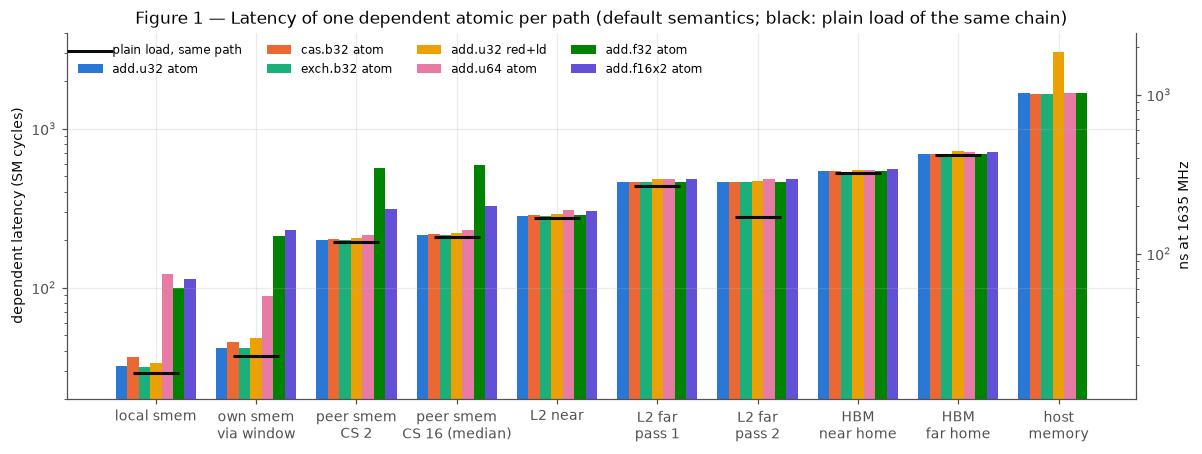

In [3]:
def lat(target, op, kind="atom", sem="default", scope="default", cs=None, p=None, variant=None):
    d = LS[(LS.target == target) & (LS.op == op) & (LS.kind == kind) & (LS["sem"] == sem) & (LS.scope == scope)]
    if cs is not None:
        d = d[d.cs == cs]
    if p is not None:
        d = d[d["pass"] == p]
    if variant is not None:
        d = d[d.variant == variant]
    return d

ROWS = [("smem", 1, "0", "local smem"), ("smem_dsmem_if", 2, "0", "own smem\nvia window"), ("dsmem", 2, "0", "peer smem\nCS 2"),
        ("dsmem", 16, "0", "peer smem\nCS 16 (median)"), ("l2_near", 1, "1", "L2 near"), ("l2_far", 1, "1", "L2 far\npass 1"),
        ("l2_far", 1, "2", "L2 far\npass 2"), ("hbm", 1, "1_near", "HBM\nnear home"), ("hbm", 1, "1_far", "HBM\nfar home"),
        ("sysmem", 1, "1", "host\nmemory")]
OPS1 = [("add.u32", "atom"), ("cas.b32", "atom"), ("exch.b32", "atom"), ("add.u32", "red+ld"), ("add.u64", "atom"), ("add.f32", "atom"),
        ("add.f16x2", "atom")]
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.8 / len(OPS1)
for j, (op, kind) in enumerate(OPS1):
    ys = []
    for t, cs, p, _ in ROWS:
        d = lat(t, op, kind, cs=cs, p=p)
        d = d[d.variant != "plus1"]
        ys.append(d.lat_cycles.median() if len(d) else np.nan)
    ax.bar(np.arange(len(ROWS)) + (j - len(OPS1) / 2 + 0.5) * w, ys, w, label=f"{op} {kind}", color=C[j % len(C)])
ref = []
for t, cs, p, _ in ROWS:
    d = lat(t, "add.u32", "ld", cs=cs, p=p)
    d = d[d.variant == "identity"]
    ref.append(d.lat_cycles.median() if len(d) else np.nan)
ax.scatter(np.arange(len(ROWS)), ref, marker="_", s=900, color=INK, zorder=5, label="plain load, same path")
ax.set_xticks(np.arange(len(ROWS)), [r[3] for r in ROWS])
ax.set_yscale("log")
ax.set_ylabel("dependent latency (SM cycles)")
ax.set_ylim(20, 4000)
sec = ax.secondary_yaxis("right", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3))
sec.set_ylabel("ns at 1635 MHz")
ax.legend(ncol=4, fontsize=8, loc="upper left")
ax.set_title("Figure 1 — Latency of one dependent atomic per path (default semantics; black: plain load of the same chain)")
plt.tight_layout()
plt.show()

In [4]:
# Table 1: latency (cycles) of every op at the default semantics; ld = same-chain plain load (same word format)
cols = [(t, cs, p, lab.replace("\n", " ")) for t, cs, p, lab in ROWS]
ops = ["add.u32", "add.u64", "inc.u32", "min.s32", "max.u32", "and.b32", "exch.b32", "cas.b32", "cas.b64", "add.f32", "add.f64", "add.f16x2",
       "add.bf16x2", "add.v2.f32", "add.v4.f32", "add.v2.f16x2", "add.v4.f16x2"]
tab = {}
for op in ops:
    for kind in ["atom", "red+ld"]:
        row = {}
        for t, cs, p, lab in cols:
            d = lat(t, op, kind, cs=cs, p=p)
            d = d[d.variant.isin(["identity", "cas_fail", "reverse_chain", "host_native_atomic_0"])]
            row[lab] = d.lat_cycles.median() if len(d) else np.nan
        if not all(np.isnan(v) for v in row.values()):
            tab[(op, kind)] = row
for op, var, lab in [("cas.b32", "same_word_success", "cas.b32 succeeding (one word)"), ("cas.b64", "same_word_success", "cas.b64 succeeding (one word)"),
                     ("inc.u32", "same_word", "inc.u32 (one word)"), ("add.u32", "same_word", "add.u32 (one word)")]:
    row = {}
    for t, cs, p, l in cols:
        d = lat(t, op, "same", cs=cs, p=p, variant=var)
        row[l] = d.lat_cycles.median() if len(d) else np.nan
    tab[(lab, "atom")] = row
for fmt, lab in [("add.u32", "ld (u32 words)"), ("add.f16x2", "ld (f16x2 words)")]:
    row = {}
    for t, cs, p, l in cols:
        d = lat(t, fmt, "ld", cs=cs, p=p)
        d = d[d.variant.isin(["identity", "host_native_atomic_0"])]
        row[l] = d.lat_cycles.median() if len(d) else np.nan
    tab[(lab, "reference")] = row
T1 = pd.DataFrame(tab).T
T1.index.names = ["op", "kind"]
display(Markdown("**Table 1 — Dependent latency (SM cycles, median over SMs)**; `red+ld` = red followed by a load of the same word; HBM: median of the per-access samples (timer included)"))
display(T1.round(1))

**Table 1 — Dependent latency (SM cycles, median over SMs)**; `red+ld` = red followed by a load of the same word; HBM: median of the per-access samples (timer included)

local smem  own smem via window  peer smem CS 2  peer smem CS 16 (median)  L2 near  L2 far pass 1  L2 far pass 2  HBM near home  HBM far home  host memory
op                            kind                                                                                                                                                                 
add.u32                       atom             32.3                 41.5           200.4                     215.4    284.0          461.2          461.1          538.0         695.0       1673.6
                              red+ld           33.4                 48.0           205.9                     220.9    291.2          480.9          468.2          547.0         721.0       3037.3
add.u64                       atom            121.6                 88.9           215.3                     230.3    308.1          485.3          485.2          552.0         708.0       1662.8
                              red+ld          143.3                113.4           282.9                     297.9    316.6          506.2          493.5          560.0         734.0          NaN
inc.u32                       atom             32.3                 41.5           200.4                     215.4    283.9          460.6          460.9          538.0         695.0          NaN
                              red+ld           33.4                 48.0           204.4                     219.4    290.8          480.7          468.5          547.0         721.0          NaN
min.s32                       atom             32.3                 41.5           200.4                     215.4    283.6          460.9          460.7          538.0         696.0          NaN
                              red+ld           33.4                 48.0           205.9                     220.9    291.4          480.3          468.0          547.0         721.0          NaN
max.u32                       atom             32.3                 41.5           200.4                     215.4    283.7          460.7          460.9          538.0         695.0          NaN
                              red+ld           33.4                 48.0           205.9                     220.9    291.2          480.3          468.1          547.0         721.0          NaN
and.b32                       atom             32.3                 41.5           200.4                     215.4    283.6          461.1          461.5          538.0         695.0          NaN
                              red+ld           33.4                 48.0           205.9                     220.9    290.8          480.4          468.1          547.0         721.0          NaN
exch.b32                      atom             31.8                 41.4           200.4                     215.4    283.2          460.3          460.4          524.0         682.0       1653.5
cas.b32                       atom             36.5                 45.4           202.4                     217.4    285.9          462.6          462.7          540.0         697.0       1662.0
cas.b64                       atom             51.7                 92.5           245.5                     260.5    314.3          491.8          491.3          556.0         712.0          NaN
add.f32                       atom            100.1                212.5           562.4                     592.4    285.8          463.1          462.8          540.0         697.0       1677.1
                              red+ld          121.7                226.4           726.3                     771.3    293.4          483.1          470.9          549.0         723.0          NaN
add.f64                       atom            119.6                240.3           589.5                     619.5    310.4          487.3          487.3          554.0         710.0          NaN
                              red+ld          143.3                251.5           755.6                     800.6    318

### 4.2 Global atomics execute at the line's home partition

The L2 protocol walks the same lines three times after cleaning the L2. The lines were last written by an SM of their home partition, so they live only at their home (table 2, median over the 8 issuing SMs, one per GPC):
- **Pass 1** is the first access: near for lines homed in the issuer's partition, far for the others.
- **Pass 2** repeats the walk without cleaning. A plain load becomes near, because pass 1 left a copy in the reader's partition.
- **Pass 2ld** reads the lines with plain loads after the atomic passes.

Figure 2 shows the per-access distributions (one sample per operation, timer included) of the same protocol and of the HBM walk.

In [5]:
L2 = LS[LS.target.isin(["l2_near", "l2_far"]) & (LS["sem"] == "default")]
rows = []
for (op, kind) in [("add.u32", "atom"), ("cas.b32", "atom"), ("exch.b32", "atom"), ("add.u32", "red+ld"), ("add.f32", "atom"), ("add.u64", "atom"),
                   ("add.v4.f32", "atom"), ("add.u32", "st+ld"), ("add.u32", "ld")]:
    r = {"op": op, "kind": kind}
    for t in ["l2_near", "l2_far"]:
        for p in ["1", "2"]:
            d = L2[(L2.target == t) & (L2.op == op) & (L2.kind == kind) & (L2["pass"] == p) & (L2.variant != "plus1")]
            r[f"{t} pass {p}"] = d.lat_cycles.median()
        d = L2[(L2.target == t) & (L2.op == op) & (L2.kind == "ld") & (L2["pass"] == "2ld") & (L2.variant == f"after_{kind}")]
        r[f"{t} 2ld"] = d.lat_cycles.median() if kind != "ld" else np.nan
    rows.append(r)
T2 = pd.DataFrame(rows).set_index(["op", "kind"])
display(Markdown("**Table 2 — L2 protocol (SM cycles, median of the 8 issuing SMs)**"))
display(T2.round(1))
per_sm = fix_2ld(LAT[(LAT.run_id == SRC["l2"])])
per_sm = per_sm[(per_sm["pass"] != "2ld") | (per_sm.after == "atom")]  # 2ld column: the plain load after the atomic passes
g = per_sm.groupby(["smid_src", "target", "op", "kind", "pass", "hops"]).total_cycles.median().unstack("hops")
g = ((g[16384] - g[4096]) / 12288).rename("lat").reset_index()
g = g[(g.op == "add.u32") & (g.kind.isin(["atom", "ld"]))].pivot_table(index="smid_src", columns=["target", "kind", "pass"], values="lat")
g.index = [f"SM {s} (GPC {PART.set_index('smid').gpc[s]}, partition {PART.set_index('smid').partition[s]})" for s in g.index]
display(Markdown("**Per issuing SM** (add.u32 atom and plain load, slopes)"))
display(g.round(1))

**Table 2 — L2 protocol (SM cycles, median of the 8 issuing SMs)**

l2_near pass 1  l2_near pass 2  l2_near 2ld  l2_far pass 1  l2_far pass 2  l2_far 2ld
op         kind                                                                                         
add.u32    atom             284.0           283.8        272.9          461.2          461.1       433.8
cas.b32    atom             285.9           286.2        272.9          462.6          462.7       433.8
exch.b32   atom             283.2           283.2        272.9          460.3          460.4       433.7
add.u32    red+ld           291.2           291.1        273.0          480.9          468.2       434.1
add.f32    atom             285.8           285.8        272.9          463.1          462.8       433.6
add.u64    atom             308.1           308.1        294.4          485.3          485.2       455.4
add.v4.f32 atom             313.0           312.9        273.1          489.8          490.1       433.9
add.u32    st+ld            272.0           272.1        273.1          432.6          278.1       279.3
           ld               272.8           272.8          NaN          433.9          279.4         NaN

**Per issuing SM** (add.u32 atom and plain load, slopes)

target                       l2_far                             l2_near                            
kind                           atom            ld                  atom            ld              
pass                              1      2      1      2    2ld       1      2      1      2    2ld
SM 0.0 (GPC 0, partition 0)   462.0  462.1  434.3  279.5  432.8   284.4  284.4  272.4  272.6  272.4
SM 2.0 (GPC 1, partition 1)   462.3  462.3  433.5  279.0  433.3   284.5  284.5  272.6  272.6  273.1
SM 4.0 (GPC 2, partition 1)   461.5  461.1  432.6  278.3  432.7   284.1  284.1  272.7  272.5  272.7
SM 6.0 (GPC 3, partition 1)   460.6  460.0  434.3  279.3  433.8   282.6  282.7  273.0  273.0  272.9
SM 8.0 (GPC 4, partition 1)   464.2  464.2  438.0  283.0  438.0   286.5  286.5  276.7  276.7  276.8
SM 10.0 (GPC 5, partition 0)  460.2  459.9  435.0  279.9  434.6   283.4  283.4  273.9  273.9  273.4
SM 12.0 (GPC 6, partition 0)  460.4  460.6  433.3  279.5  434.7   282.5  282.9  273.0  273.0  272.8
SM 14.0 (GPC 7, partition 0)  460.9  461.1  432.6  278.6  433.7   283.9  283.6  272.1  272.2  272.5

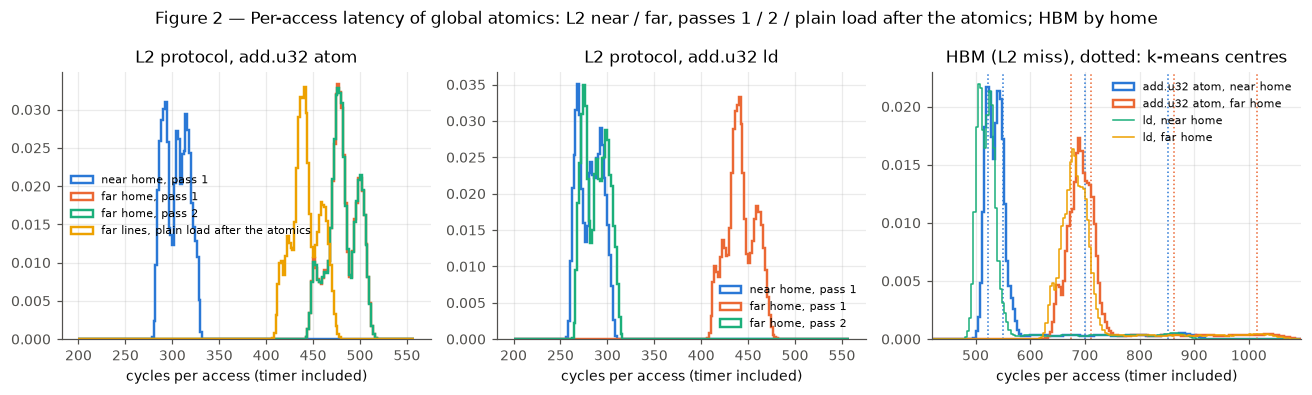

HBM add.u32 atom, near-homed lines: k = 4 classes, centres [523.3 550.4 701.  852.5] cycles
HBM add.u32 atom, far-homed lines: k = 4 classes, centres [ 674.5  710.9  862.9 1014.2] cycles
HBM add.u32 atom samples above 1096 cycles (not drawn): 0.080 % (max 1322 cycles)


In [6]:
FINE = fix_2ld(read_ids("12__atomics__fine.csv", [SRC["l2fine"], SRC["hbm"]], dtype={"pass": str}))
HIST = read_ids("12__atomics__fine_hist.csv", [SRC["hbm"]], dtype={"pass": str})
pmap = PART.set_index("smid").partition
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
f = FINE[(FINE.run_id == SRC["l2fine"])]
bins = np.arange(200, 560, 2)
for ax, (op, kind) in zip(axs[:2], [("add.u32", "atom"), ("add.u32", "ld")]):
    for i, (t, p) in enumerate([("l2_near", "1"), ("l2_far", "1"), ("l2_far", "2"), ("l2_far", "2ld")]):
        if kind == "ld" and p == "2ld":
            continue
        d = f[(f.op == op) & (f.kind == kind) & (f.target == t) & (f["pass"] == p)] if p != "2ld" else \
            f[(f.op == op) & (f.kind == "ld") & (f.target == t) & (f["pass"] == "2ld") & (f.after == kind)]
        if kind == "atom" and p == "2ld":
            lab = "far lines, plain load after the atomics"
        else:
            lab = f"{t.replace('l2_', '')} home, pass {p}"
        ax.hist(d.cycles, bins=bins, histtype="step", lw=1.6, color=C[i], label=lab, density=True)
    ax.set_title(f"L2 protocol, {op} {kind}")
    ax.set_xlabel("cycles per access (timer included)")
    ax.legend(fontsize=7)
ax = axs[2]
h = FINE[(FINE.run_id == SRC["hbm"])]
h = h.assign(rel=np.where(h.home_partition == h.smid.map(pmap), "near", "far"))
bins = np.arange(420, 1100, 4)
centres = {}
for i, rel in enumerate(["near", "far"]):
    d = h[h.rel == rel]
    ax.hist(d.cycles, bins=bins, histtype="step", lw=1.6, color=C[i], density=True, label=f"add.u32 atom, {rel} home")
    k, (c, b, sse) = kmeans_elbow(d.cycles.clip(upper=1500).values[::7])
    centres[rel] = (k, c)
    for x in c:
        ax.axvline(x, color=C[i], ls=":", lw=1)
hh = HIST[(HIST.op == "add.u32") & (HIST.kind == "ld")]
hh = hh.assign(rel=np.where(hh.home_partition == hh.smid.map(pmap), "near", "far"))
for i, rel in enumerate(["near", "far"]):
    d = hh[hh.rel == rel]
    w, _ = np.histogram(d.cycles, bins=bins, weights=d["count"])
    ax.step(bins[:-1], w / d["count"].sum() / np.diff(bins)[0], where="post", color=C[i + 2], lw=1, label=f"ld, {rel} home")
over = (h.cycles > bins[-1]).mean()
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel("cycles per access (timer included)")
ax.set_title("HBM (L2 miss), dotted: k-means centres")
ax.legend(fontsize=7)
fig.suptitle("Figure 2 — Per-access latency of global atomics: L2 near / far, passes 1 / 2 / plain load after the atomics; HBM by home")
plt.tight_layout()
plt.show()
for rel, (k, c) in centres.items():
    print(f"HBM add.u32 atom, {rel}-homed lines: k = {k} classes, centres {np.round(c, 1)} cycles")
print(f"HBM add.u32 atom samples above {bins[-1]} cycles (not drawn): {100 * over:.3f} % (max {h.cycles.max()} cycles)")

### 4.3 Memory-ordering semantics and scope

Table 3a lists the latency of the same dependent chains with explicit semantics and scope (add.u32 `atom`, add.u32 `red`+ld, cas.b32). On global targets, the L2 values are from SMs 0 and 2 (one per partition).

In [7]:
S = LS[(LS.op.isin(["add.u32", "cas.b32"])) & (LS.kind.isin(["atom", "red+ld"])) & (LS.variant.isin(["identity", "cas_fail"]))]
S = S[S["pass"].isin(["0", "1"]) & ((S.target != "dsmem") | (S.cs == 2))]
S = S.assign(semantics=S["sem"] + "." + S.scope)
order = ["default.default", "relaxed.cta", "relaxed.cluster", "relaxed.gpu", "relaxed.sys", "acq_rel.cta", "release.cta", "acq_rel.cluster",
         "release.cluster", "acq_rel.gpu", "release.gpu", "acq_rel.sys", "release.sys"]
T3a = S.pivot_table(index=["op", "kind", "semantics"], columns="target", values="lat_cycles", aggfunc="median")
T3a = T3a.reindex(columns=[c for c in ["smem", "smem_dsmem_if", "dsmem", "l2_near", "l2_far", "sysmem"] if c in T3a.columns])
T3a = T3a.reset_index()
T3a["o"] = T3a.semantics.map({s: i for i, s in enumerate(order)})
T3a = T3a.sort_values(["op", "kind", "o"]).drop(columns="o").set_index(["op", "kind", "semantics"])
display(Markdown("**Table 3a — Latency (SM cycles) by semantics and scope**; dsmem = cluster of 2"))
display(T3a.round(1))
F = forms()
T3b = F.pivot_table(index=["op", "kind"], columns="space", values="sass", aggfunc="first")[["shared::cta", "shared::cluster", "global"]]
display(Markdown("**Table 3b — SASS of each operation** (default semantics; `CAS` / `CAST.SPIN` = compare-and-swap loop; a `.shared::cluster` op has one form per run-time case: own CTA, peer CTA, generic global)"))
with pd.option_context("display.max_colwidth", 80):
    display(T3b)

**Table 3a — Latency (SM cycles) by semantics and scope**; dsmem = cluster of 2

target                            smem  smem_dsmem_if   dsmem  l2_near  l2_far
op      kind   semantics                                                      
add.u32 atom   default.default    32.3           41.5   200.4    284.0   461.2
               relaxed.cta        32.3           41.5   200.4    283.9   460.8
               relaxed.cluster    32.3           41.5   200.4    284.3   461.7
               relaxed.gpu        32.3           41.5   200.4    284.1   460.3
               relaxed.sys        32.3           41.5   200.4    284.2   461.8
               acq_rel.cta        37.6           47.1   207.6    290.0   466.7
               acq_rel.cluster   293.0          302.9   463.4    676.3   992.8
               acq_rel.gpu       293.0          302.9   463.4    676.4   992.4
               acq_rel.sys      1279.4         1286.4  1273.2   1366.0  1547.3
        red+ld default.default    33.4           48.0   205.9    291.2   480.9
               relaxed.cta        33.4           48.0   205.9    291.8   480.0
               relaxed.cluster    33.4           48.0   205.9    291.5   480.4
               relaxed.gpu        33.4           48.0   205.9    291.2   479.7
               relaxed.sys        33.4           48.0   205.9    291.4   480.8
               release.cta        37.4           52.0   210.1    295.2   483.3
               release.cluster   291.4          306.0   464.1    680.4  1007.7
               release.gpu       291.4          306.0   464.1    680.4  1009.2
               release.sys      1294.9         1316.5  1274.5   1370.8  1561.2
cas.b32 atom   default.default    36.5           45.4   202.4    285.9   462.6
               relaxed.cta        36.5           45.4   202.4    285.8   464.0
               relaxed.cluster    36.5           45.4   202.4    286.0   463.0
               relaxed.gpu        36.5           45.4   202.4    286.1   463.0
               relaxed.sys        36.5           45.4   202.4    286.2   463.4
               acq_rel.cta        42.4           52.1   210.9    292.9   471.3
               acq_rel.cluster   298.3          307.1   465.9    679.0   995.2
               acq_rel.gpu       298.3          307.1   465.9    679.3   995.0
               acq_rel.sys      1278.9         1295.7  1274.2   1369.7  1547.7

**Table 3b — SASS of each operation** (default semantics; `CAS` / `CAST.SPIN` = compare-and-swap loop; a `.shared::cluster` op has one form per run-time case: own CTA, peer CTA, generic global)

space                     shared::cta                                                          shared::cluster                             global
op           kind                                                                                                                                
add.bf16x2   atom     ATOMS.CAST.SPIN                                        ATOM.E.ADD.BF16 + ATOMS.CAST.SPIN                   ATOMG.E.ADD.BF16
             red      ATOMS.CAST.SPIN                                        ATOM.E.ADD.BF16 + ATOMS.CAST.SPIN                    REDG.E.ADD.BF16
add.f16x2    atom     ATOMS.CAST.SPIN                                         ATOM.E.ADD.F16 + ATOMS.CAST.SPIN                    ATOMG.E.ADD.F16
             red      ATOMS.CAST.SPIN                                         ATOM.E.ADD.F16 + ATOMS.CAST.SPIN                     REDG.E.ADD.F16
add.f32      atom     ATOMS.CAST.SPIN    ATOM.E.ADD.F32.FTZ.RN.STRONG.GPU + ATOM.E.CAST.SPIN + ATOMS.CAST.SPIN  ATOMG.E.ADD.F32.FTZ.RN.STRONG.GPU
             red      ATOMS.CAST.SPIN    ATOM.E.ADD.F32.FTZ.RN.STRONG.GPU + ATOM.E.CAST.SPIN + ATOMS.CAST.SPIN   REDG.E.ADD.F32.FTZ.RN.STRONG.GPU
add.f64      atom  ATOMS.CAST.SPIN.64  ATOM.E.ADD.F64.RN.STRONG.GPU + ATOM.E.CAST.SPIN.64 + ATOMS.CAST.SPIN.64      ATOMG.E.ADD.F64.RN.STRONG.GPU
             red   ATOMS.CAST.SPIN.64  ATOM.E.ADD.F64.RN.STRONG.GPU + ATOM.E.CAST.SPIN.64 + ATOMS.CAST.SPIN.64       REDG.E.ADD.F64.RN.STRONG.GPU
add.u32      atom           ATOMS.ADD                                                    ATOM.E.ADD.STRONG.GPU             ATOMG.E.ADD.STRONG.GPU
             red            ATOMS.ADD                                                    ATOM.E.ADD.STRONG.GPU              REDG.E.ADD.STRONG.GPU
add.u64      atom  ATOMS.CAST.SPIN.64                            ATOM.E.ADD.64.STRONG.GPU + ATOMS.CAST.SPIN.64          ATOMG.E.ADD.64.STRONG.GPU
             red   ATOMS.CAST.SPIN.64                            ATOM.E.ADD.64.STRONG.GPU + ATOMS.CAST.SPIN.64           REDG.E.ADD.64.STRONG.GPU
add.v2.f16x2 atom                 NaN                                                                      NaN                    ATOMG.E.ADD.F16
             red                  NaN                                                                      NaN                     REDG.E.ADD.F16
add.v2.f32   atom                 NaN                                                                      NaN                    ATOMG.E.ADD.F32
             red                  NaN                                                                      NaN                     REDG.E.ADD.F32
add.v4.f16x2 atom                 NaN                                                                      NaN                    ATOMG.E.ADD.F16
             red                  NaN                                                                      NaN                     REDG.E.ADD.F16
add.v4.f32   atom                 NaN                                                                      NaN                    ATOMG.E.ADD.F32
             red                  NaN                                                                      NaN                     REDG.E.ADD.F32
and.b32      atom           ATOMS.AND                                                    ATOM.E.AND.STRONG.GPU             ATOMG.E.AND.STRONG.GPU
             red            ATOMS.AND                                                    ATOM.E.AND.STRONG.GPU              REDG.E.AND.STRONG.GPU
cas.b32      atom           ATOMS.CAS                                                    ATOM.E.CAS.STRONG.GPU             ATOMG.E.CAS.STRONG.GPU
cas.b64      atom        ATOMS.CAS.64                                                 ATOM.E.CAS.64.STRONG.GPU          ATOMG.E.CAS.64.STRONG.GPU
exch.b32     atom          ATOMS.EXCH                                                   ATOM.E.EXCH.STRONG.GPU            ATOMG.E.EXCH.STRONG.GPU
inc.u32      atom           ATOMS.INC                     

### 4.4 Remote (DSMEM) atomics per SM pair

Every directed pair of SMs that can share a cluster (full waves of clusters of 16, 8, 4 and 2) chased the other SM's chain with add.u32 `atom`, cas.b32, add.u32 `red`+ld and a plain load (4096 hops). Figure 3a shows the distribution of the per-pair difference to the plain load of the same pair in the same run. Figure 3b compares the per-pair load and atomic latency with the latency matrix of the same pairs from an independent load-only measurement of this card.

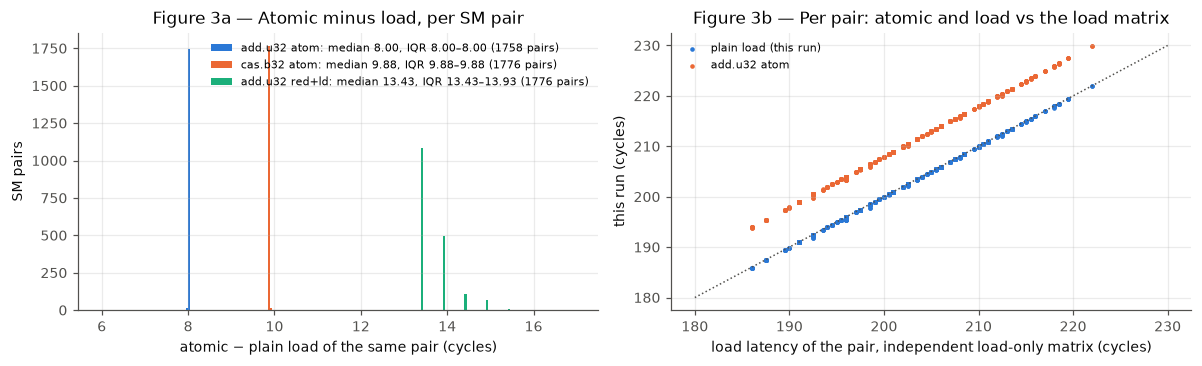

1872 directed pairs; this run's plain load − independent matrix: median -0.052, max |Δ| 0.72 cycles


**Lone clusters** (rank 0 → each peer; median over peers, cycles)

cs                    2      4      16
op         kind                       
add.bf16x2 atom    310.1  334.1  325.1
           red+ld  490.1  536.2  520.1
add.f16x2  atom    310.1  334.1  325.1
           ld      209.0  232.0  224.0
           red+ld  490.1  536.2  520.1
add.f32    atom    562.4  608.5  592.4
           red+ld  726.3  795.3  771.3
add.f64    atom    589.5  635.5  619.5
           red+ld  755.6  824.6  800.6
add.u32    atom    200.4  223.4  215.4
           ld      192.4  215.4  207.4
           red+ld  205.9  228.9  220.9
add.u64    atom    215.3  238.3  230.3
           red+ld  282.9  305.9  297.9
and.b32    atom    200.4  223.4  215.4
           red+ld  205.9  228.9  220.9
cas.b32    atom    202.4  225.4  217.4
cas.b64    atom    245.5  268.5  260.5
exch.b32   atom    200.4  223.4  215.4
inc.u32    atom    200.4  223.4  215.4
           red+ld  204.4  227.4  219.4
max.u32    atom    200.4  223.4  215.4
           red+ld  205.9  228.9  220.9
min.s32    atom    200.4  223.4  215.4
           red+ld  205.9  228.9  220.9

In [8]:
pp = PAIRS.pivot_table(index=["smid_src", "smid_dst"], columns=["op", "kind"], values="cycles_per_op", aggfunc="first")
pp.columns = [f"{a} {b}" for a, b in pp.columns]
ld10 = PAIRS.groupby(["smid_src", "smid_dst"]).ld10_cycles.first()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for i, c in enumerate(["add.u32 atom", "cas.b32 atom", "add.u32 red+ld"]):
    dd = (pp[c] - pp["add.u32 ld"]).dropna()
    axs[0].hist(dd, bins=np.arange(6, 17, 0.05), color=C[i], label=f"{c}: median {dd.median():.2f}, IQR {dd.quantile(.25):.2f}–{dd.quantile(.75):.2f} ({len(dd)} pairs)")
axs[0].set_xlabel("atomic − plain load of the same pair (cycles)")
axs[0].set_ylabel("SM pairs")
axs[0].legend(fontsize=7)
axs[0].set_title("Figure 3a — Atomic minus load, per SM pair")
j = pp.join(ld10)
axs[1].scatter(j.ld10_cycles, j["add.u32 ld"], s=4, color=C[0], label="plain load (this run)")
axs[1].scatter(j.ld10_cycles, j["add.u32 atom"], s=4, color=C[1], label="add.u32 atom")
axs[1].plot([180, 230], [180, 230], color=INK2, ls=":", lw=1)
axs[1].set_xlabel("load latency of the pair, independent load-only matrix (cycles)")
axs[1].set_ylabel("this run (cycles)")
axs[1].legend(fontsize=7)
axs[1].set_title("Figure 3b — Per pair: atomic and load vs the load matrix")
plt.tight_layout()
plt.show()
print(f"{len(pp)} directed pairs; this run's plain load − independent matrix: median {(j['add.u32 ld'] - j.ld10_cycles).median():+.3f}, "
      f"max |Δ| {(j['add.u32 ld'] - j.ld10_cycles).abs().max():.2f} cycles")
lone = LS[(LS.target == "dsmem") & (LS["sem"] == "default") & (LS.variant.isin(["identity", "cas_fail", "reverse_chain"]))]
display(Markdown("**Lone clusters** (rank 0 → each peer; median over peers, cycles)"))
display(lone.pivot_table(index=["op", "kind"], columns="cs", values="lat_cycles", aggfunc="median").round(1))

### 4.5 Throughput of one SM

Figure 4 shows the operations per cycle of one CTA (one SM) versus threads, one line per number of independent operations per thread and step, for add.u32 `red` and `atom`. The payload rate (operations × 4 B) is on the right axis; for local shared memory the 128 B/cycle of a conflict-free shared-memory access is dotted. Table 4 lists the best configuration of every target, operation and pattern at 1024 threads, and the same with a CTA on every SM at once.

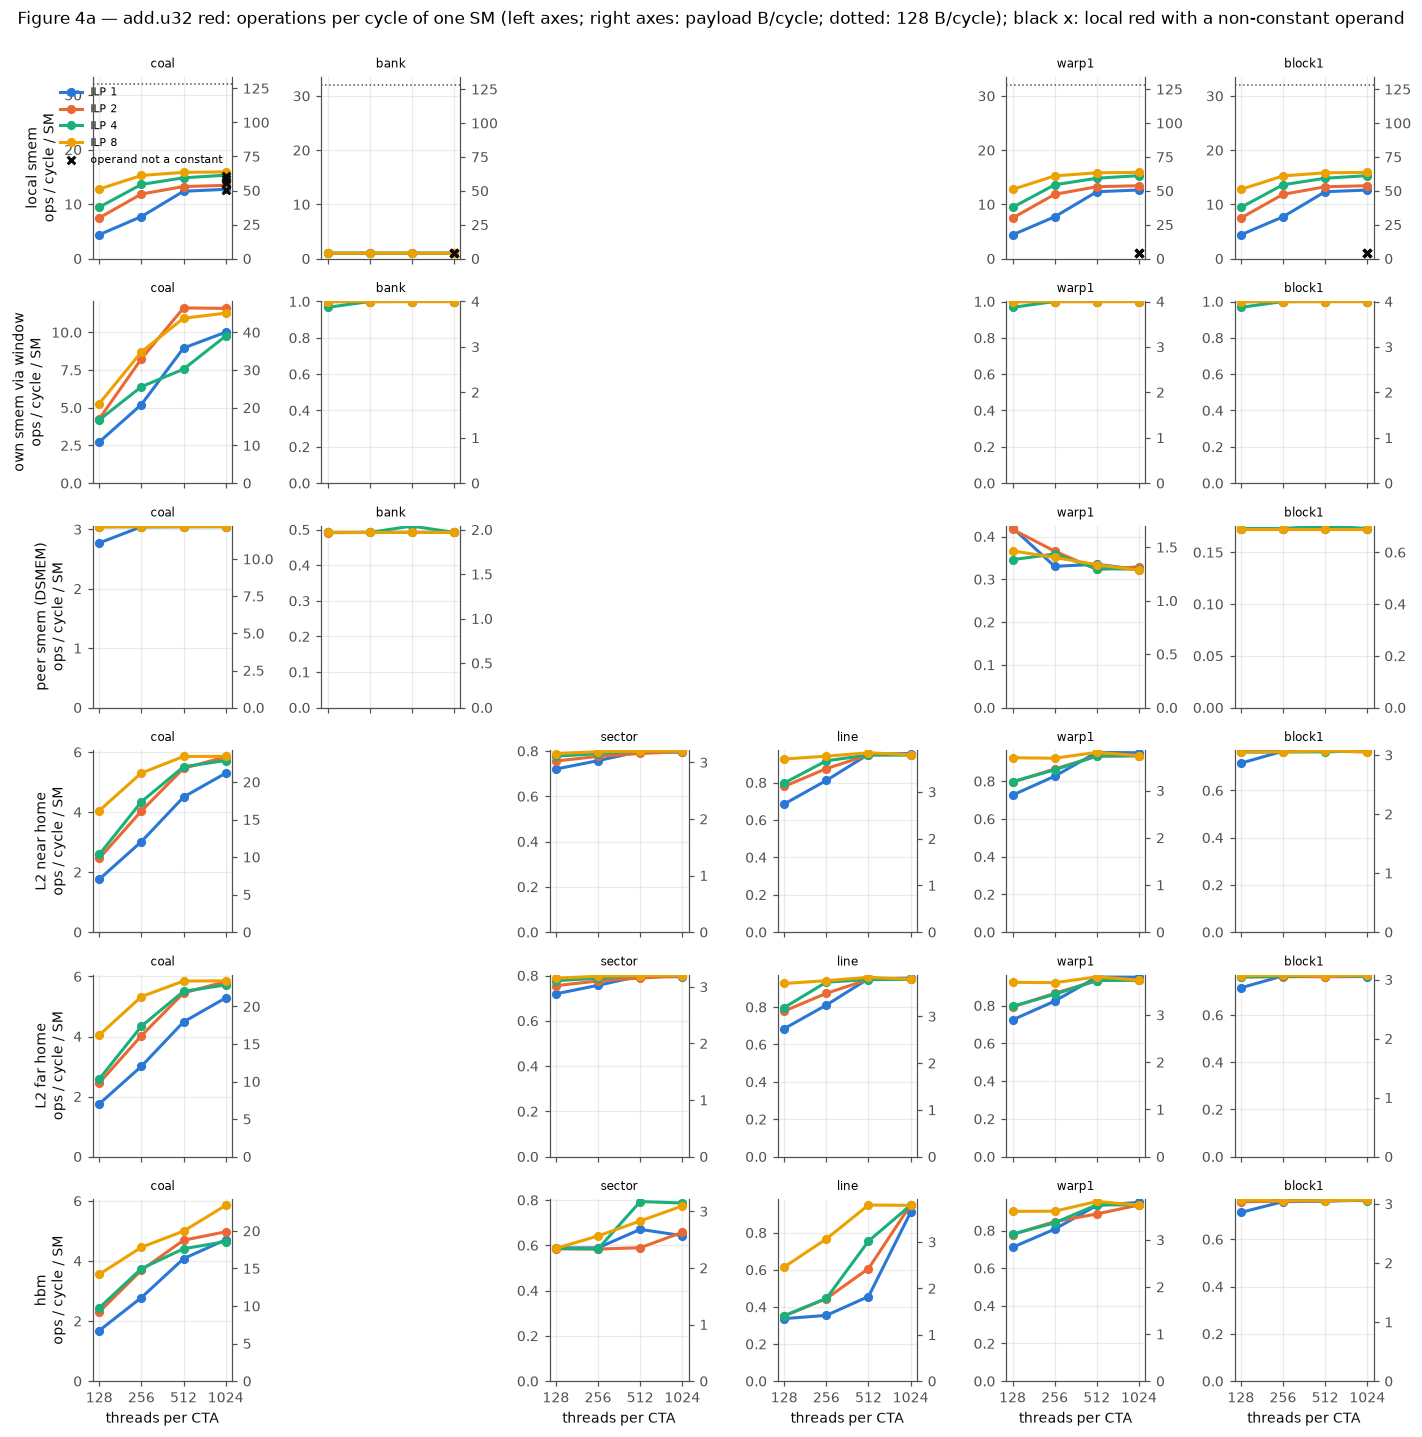

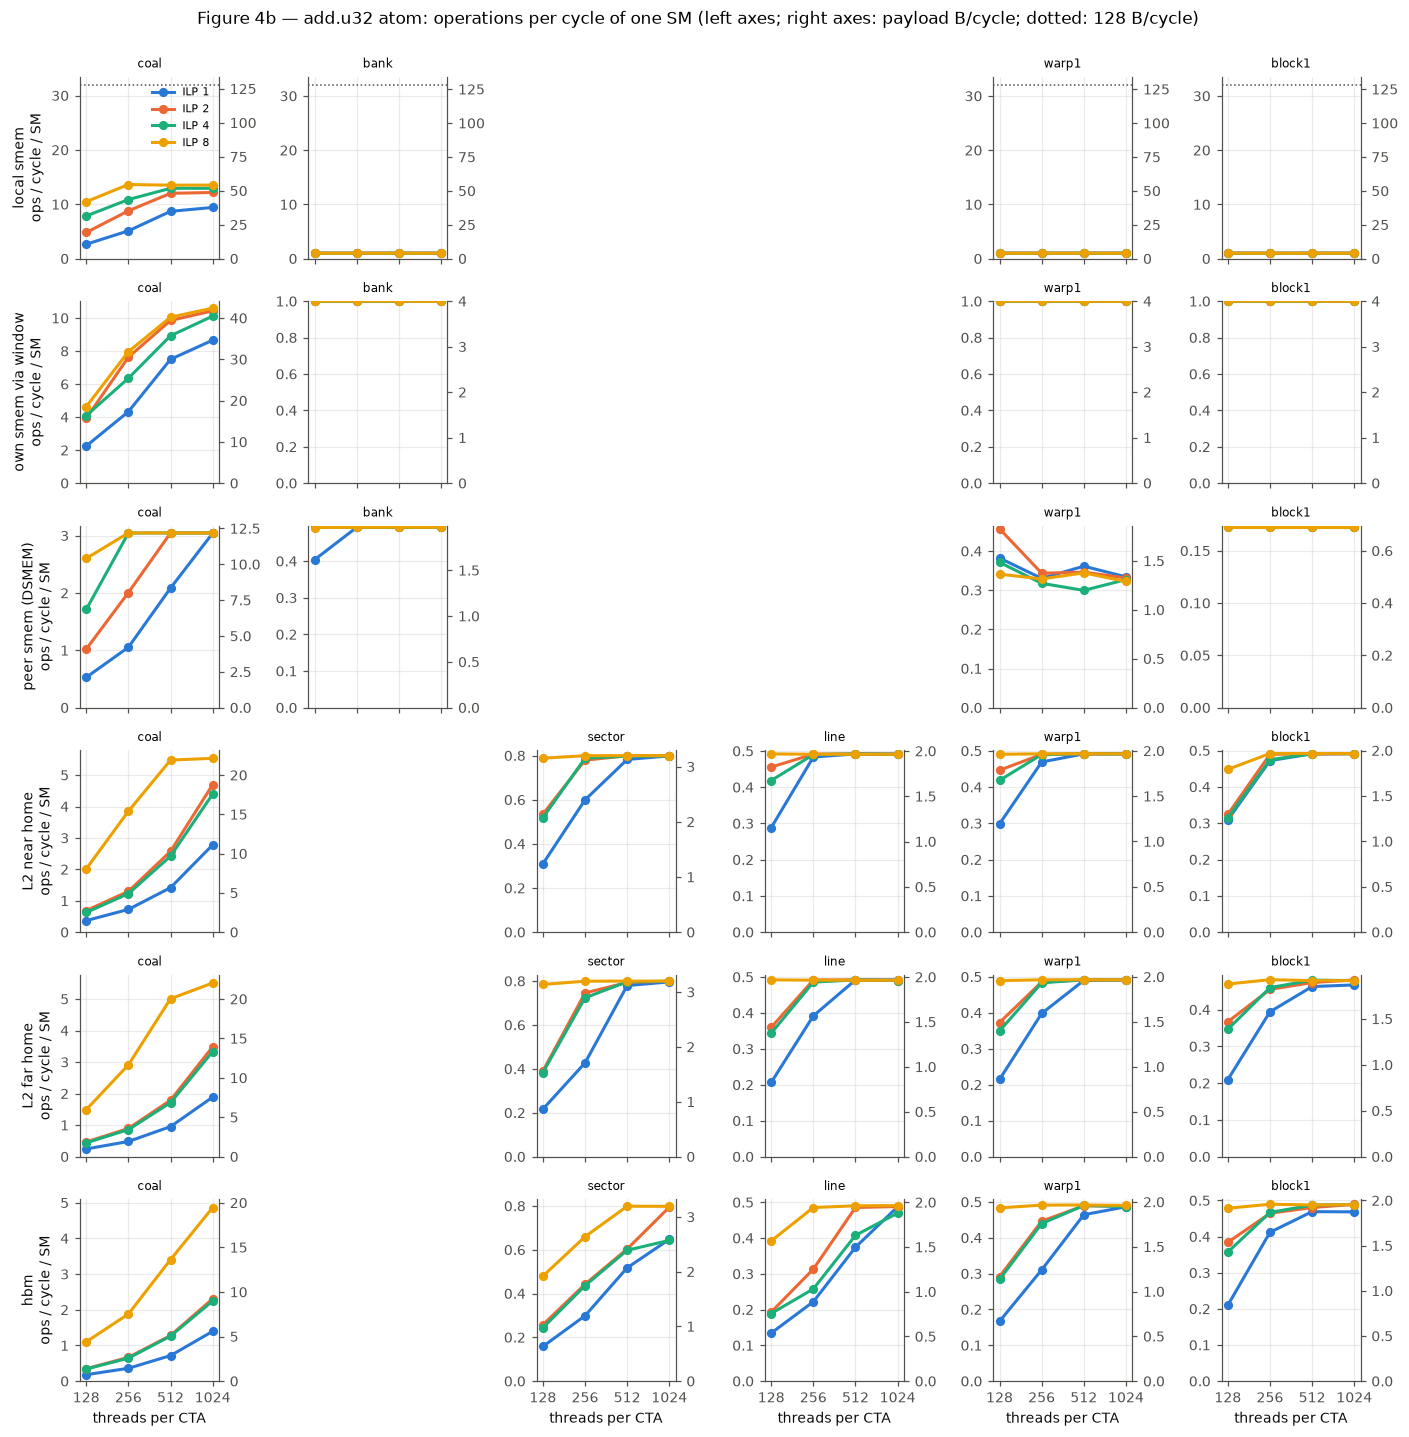

In [9]:
K2 = read_ids("12__atomics__throughput_sm.csv", [SRC["k2"], SRC["k2all"], SRC["k2x"]])
K2 = K2[K2.discard.isna()]
k2 = K2[K2.run_id == SRC["k2"]]
tg = ["smem", "smem_dsmem_if", "dsmem", "l2_near", "l2_far", "hbm"]
pats = ["coal", "bank", "sector", "line", "warp1", "block1"]
for kind in ["red", "atom"]:
    fig, axs = plt.subplots(len(tg), len(pats), figsize=(13, 13), sharex=True)
    for i, t in enumerate(tg):
        for j, p in enumerate(pats):
            ax = axs[i, j]
            d = k2[(k2.target == t) & (k2.pattern == p) & (k2.op == "add.u32") & (k2.kind == kind)]
            if d.empty:
                ax.axis("off")
                continue
            m = d.groupby(["ilp", "threads"]).ops_per_cycle.median().unstack("ilp")
            for c, ilp in enumerate(m.columns):
                ax.plot(m.index, m[ilp], marker="o", color=C[c], label=f"ILP {ilp}")
            if t == "smem":
                ax.axhline(128 / 4, color=INK2, ls=":", lw=1)
                if kind == "red":  # control: the same red with a run-time operand (plain ATOMS.ADD), 1024 threads
                    xr = K2[(K2.run_id == SRC["k2x"]) & (K2.placement == "1sm") & (K2.pattern == p)].groupby("ilp").ops_per_cycle.median()
                    if len(xr):
                        ax.scatter([1024] * len(xr), xr.values, marker="x", color=INK, zorder=5, label="operand not a constant")
            ax.set_xscale("log", base=2)
            ax.set_xticks([128, 256, 512, 1024], ["128", "256", "512", "1024"])
            ax.set_ylim(bottom=0)
            ax.set_title(p, fontsize=8)
            if j == 0:
                ax.set_ylabel(f"{TARGET_LABEL.get(t, t)}\nops / cycle / SM")
            if i == len(tg) - 1:
                ax.set_xlabel("threads per CTA")
            ax.secondary_yaxis("right", functions=(lambda o: o * 4, lambda b: b / 4))
    axs[0, 0].legend(fontsize=7)
    fig.suptitle(f"Figure 4{'a' if kind == 'red' else 'b'} — add.u32 {kind}: operations per cycle of one SM (left axes; right axes: payload B/cycle; "
                 f"dotted: 128 B/cycle){'; black x: local red with a non-constant operand' if kind == 'red' else ''}", y=1.0)
    plt.tight_layout()
    plt.show()

In [10]:
best = K2[(K2.threads == 1024)].groupby(["placement", "target", "op", "kind", "pattern", "ilp"]).ops_per_cycle.median().reset_index()
best = best.loc[best.groupby(["placement", "target", "op", "kind", "pattern"]).ops_per_cycle.idxmax()]
best["placement"] = best.placement.map({"1sm": "1 SM", "132sm": "132 SMs (median SM)"})
T4 = best.pivot_table(index=["target", "op", "kind"], columns=["placement", "pattern"], values="ops_per_cycle")
display(Markdown("**Table 4 — Best operations per cycle per SM at 1024 threads** (over ILP 1–8); ld / st = plain loads / stores of the same addresses; "
                 "red_rt = local red.add.u32 whose operand is not a compile-time constant"))
display(T4.round(2))

**Table 4 — Best operations per cycle per SM at 1024 threads** (over ILP 1–8); ld / st = plain loads / stores of the same addresses; red_rt = local red.add.u32 whose operand is not a compile-time constant

placement                      1 SM                                132 SMs (median SM)                   
pattern                        bank block1  coal line sector warp1                bank block1  coal warp1
target        op        kind                                                                             
dsmem         add.f16x2 atom    NaN    NaN   2.7  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   2.7  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              add.f32   atom    NaN    NaN   1.4  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   1.4  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              add.u32   atom    0.5    0.2   3.0  NaN    NaN   0.3                 0.3    0.1   1.7   0.2
                        ld      NaN    NaN   4.3  NaN    NaN   NaN                 NaN    NaN   2.9   NaN
                        red     0.5    0.2   3.0  NaN    NaN   0.3                 0.3    0.1   1.7   0.2
                        st      NaN    NaN   4.3  NaN    NaN   NaN                 NaN    NaN   3.9   NaN
              add.u64   atom    NaN    NaN   1.8  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   1.8  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              cas.b32   atom    NaN    NaN   1.6  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
hbm           add.f16x2 atom    NaN    NaN   4.6  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   4.8  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              add.f32   atom    NaN    NaN   4.6  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   4.8  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              add.u32   atom    NaN    0.5   4.9  0.5    0.8   0.5                 NaN    0.2   1.6   0.3
                        ld      NaN    NaN   5.3  NaN    NaN   NaN                 NaN    NaN   3.1   NaN
                        red     NaN    0.8   5.8  0.9    0.8   0.9                 NaN    0.2   1.6   0.4
                        st      NaN    NaN   6.0  NaN    NaN   NaN                 NaN    NaN   3.3   NaN
              add.u64   atom    NaN    NaN   3.2  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   3.2  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              cas.b32   atom    NaN    NaN   3.2  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
l2_far        add.f16x2 atom    NaN    NaN   5.6  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   6.0  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              add.f32   atom    NaN    NaN   5.6  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   6.0  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              add.u32   atom    NaN    0.5   5.5  0.5    0.8   0.5                 NaN    0.2   1.2   0.2
                        ld      NaN    NaN   5.6  NaN    NaN   NaN                 NaN    NaN   5.6   NaN
                        red     NaN    0.8   5.8  1.0    0.8   0.9                 NaN    0.1   2.2   0.3
                        st      NaN    NaN   6.0  NaN    NaN   NaN                 NaN    NaN   2.7   NaN
              add.u64   atom    NaN    NaN   3.2  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   3.2  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
              cas.b32   atom    NaN    NaN   3.2  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
l2_near       add.f16x2 atom    NaN    NaN   5.6  NaN    NaN   NaN                 NaN    NaN   NaN   NaN
                        red     NaN    NaN   6.0  NaN    NaN   NaN            

### 4.6 GPU-wide throughput of global atomics

Figure 5 shows the GPU-wide operation rate (net of the cudaEvent floor) versus footprint, for `red` and `atom` of add.u32, add.f32 and add.u64. The same kernel's plain loads and stores of the same addresses are dotted. `local` / `remote` means each partition's SMs work on lines homed in their own / the other partition.

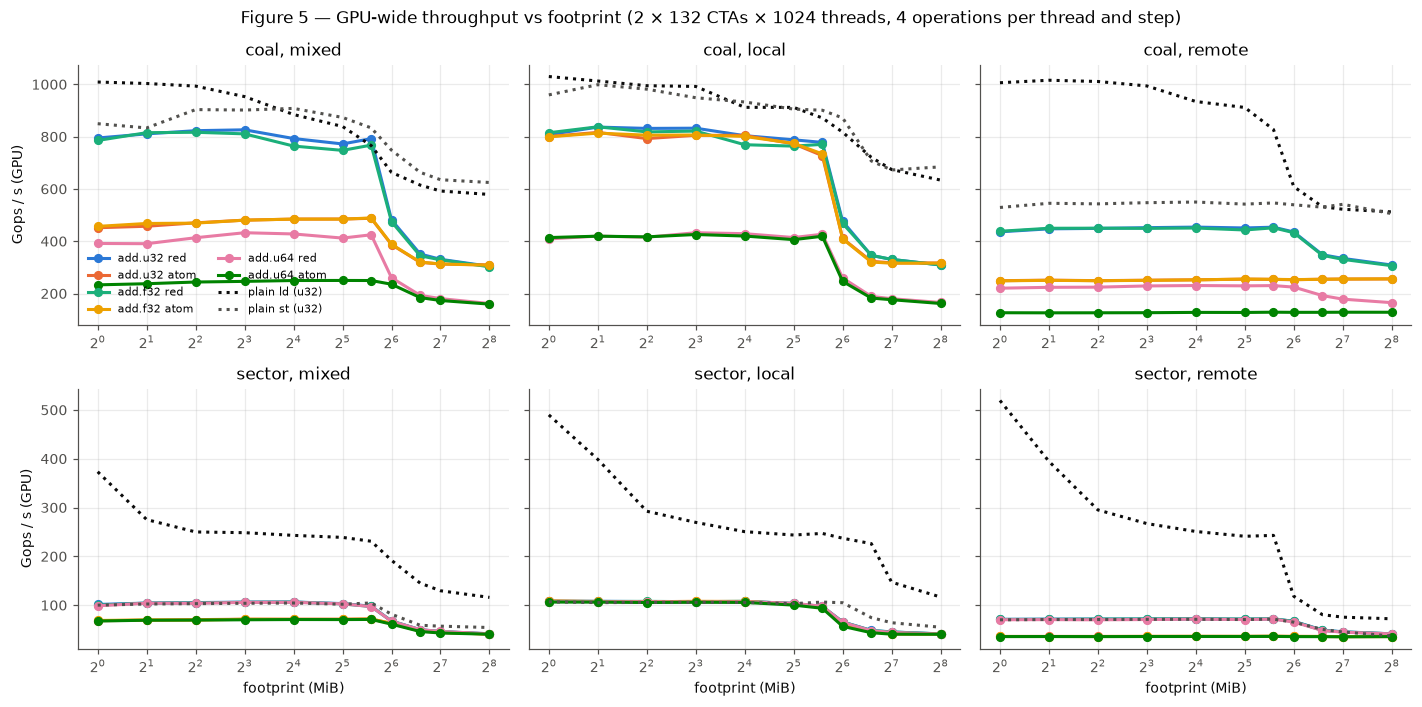

**Table 5 — GPU-wide payload rate (TB/s) at 16 and 256 MiB**

16 MiB local  16 MiB mixed  16 MiB remote  256 MiB local  256 MiB mixed  256 MiB remote
pattern op      kind                                                                                         
coal    add.f32 atom           3.2           1.9            1.0            1.3            1.2             1.0
                red            3.1           3.1            1.8            1.2            1.2             1.2
        add.u32 atom           3.2           1.9            1.0            1.3            1.2             1.0
                ld             3.7           3.5            3.7            2.5            2.3             2.0
                red            3.2           3.2            1.8            1.2            1.2             1.2
                st             3.7           3.6            2.2            2.7            2.5             2.0
        add.u64 atom           3.4           2.0            1.0            1.3            1.3             1.0
                red            3.4           3.4            1.9            1.3            1.3             1.3
sector  add.f32 atom           0.4           0.3            0.1            0.2            0.2             0.1
                red            0.4           0.4            0.3            0.2            0.2             0.2
        add.u32 atom           0.4           0.3            0.1            0.2            0.2             0.1
                ld             1.0           1.0            1.0            0.5            0.5             0.3
                red            0.4           0.4            0.3            0.2            0.2             0.2
                st             0.4           0.4            0.3            0.2            0.2             0.1
        add.u64 atom           0.8           0.6            0.3            0.3            0.3             0.3
                red            0.9           0.8            0.6            0.3            0.3             0.3

In [11]:
K3 = read_ids("12__atomics__throughput_gpu.csv", [SRC[m] for m in ["k3a", "k3b", "k3c", "k3d"]])
K3 = K3[K3.discard.isna()].copy()
K3["gops"] = K3.ops / ((K3.ms_event - EVENT_FLOOR_MS) * 1e-3) / 1e9
K3["bytes_op"] = np.where(K3.op == "add.u64", 8, 4)
K3["tbps"] = K3.gops * K3.bytes_op / 1e3
a = K3[K3.step == "k3a"]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), sharey="row")
for i, pat in enumerate(["coal", "sector"]):
    for j, var in enumerate(["mixed", "local", "remote"]):
        ax = axs[i, j]
        d = a[(a.pattern == pat) & (a.variant == var)]
        for c, (op, kind) in enumerate([("add.u32", "red"), ("add.u32", "atom"), ("add.f32", "red"), ("add.f32", "atom"), ("add.u64", "red"),
                                        ("add.u64", "atom")]):
            m = d[(d.op == op) & (d.kind == kind)].groupby("footprint_bytes").gops.median()
            ax.plot(m.index / 2**20, m.values, marker="o", color=C[c], label=f"{op} {kind}")
        for c, kind in enumerate(["ld", "st"]):
            m = d[(d.op == "add.u32") & (d.kind == kind)].groupby("footprint_bytes").gops.median()
            ax.plot(m.index / 2**20, m.values, ls=":", color=[INK, INK2][c], label=f"plain {kind} (u32)")
        ax.set_xscale("log", base=2)
        ax.set_title(f"{pat}, {var}")
        if j == 0:
            ax.set_ylabel("Gops / s (GPU)")
        if i == 1:
            ax.set_xlabel("footprint (MiB)")
axs[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle("Figure 5 — GPU-wide throughput vs footprint (2 × 132 CTAs × 1024 threads, 4 operations per thread and step)")
plt.tight_layout()
plt.show()
t5 = a[a.footprint_bytes.isin([16 << 20, 256 << 20])].pivot_table(index=["pattern", "op", "kind"], columns=["footprint_bytes", "variant"], values="tbps")
t5.columns = [f"{fp >> 20} MiB {v}" for fp, v in t5.columns]
display(Markdown("**Table 5 — GPU-wide payload rate (TB/s) at 16 and 256 MiB**"))
display(t5.round(2))

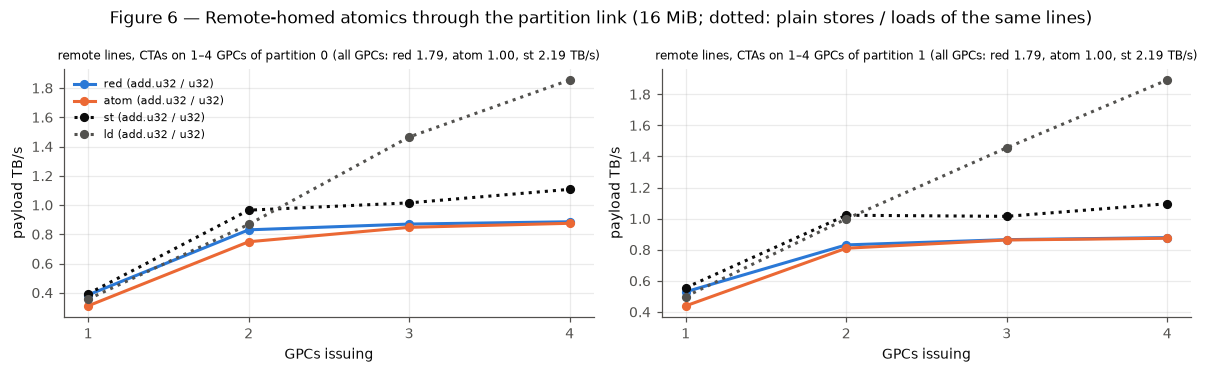

**Table 6 — One GPC alone, local lines, 16 MiB** (payload TB/s)

kind,atom,ld,red,st
gpc,,,,
0,0.3,0.4,0.4,0.4
1,0.5,0.5,0.5,0.6
2,0.5,0.5,0.5,0.6
3,0.5,0.5,0.5,0.6
4,0.5,0.5,0.6,0.6
5,0.5,0.5,0.6,0.6
6,0.5,0.5,0.6,0.6
7,0.5,0.5,0.5,0.6


In [12]:
b = K3[K3.step == "k3b"]
gp = PART.groupby("gpc").partition.first()
def label(mask):
    gs = [g for g in range(8) if mask >> g & 1]
    return "all" if len(gs) == 8 else "G" + ",".join(map(str, gs))
b = b.assign(gpcs=b.reader_gpc_mask.map(lambda m: bin(m).count("1")), part=b.reader_gpc_mask.map(lambda m: "both" if m == 0xFF else
                 f"partition {gp[[g for g in range(8) if m >> g & 1][0]]}"))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for i, p in enumerate(["partition 0", "partition 1"]):
    ax = axs[i]
    for c, kind in enumerate(["red", "atom", "st", "ld"]):
        m = b[(b.part == p) & (b.kind == kind)].groupby("gpcs").tbps.median()
        ax.plot(m.index, m.values, marker="o", color=C[c] if kind in ("red", "atom") else [INK, INK2][kind == "ld"],
                ls="-" if kind in ("red", "atom") else ":", label=f"{kind} (add.u32 / u32)")
    both = b[(b.part == "both")].groupby("kind").tbps.median()
    ax.set_title(f"remote lines, CTAs on 1–4 GPCs of {p} (all GPCs: red {both.get('red', np.nan):.2f}, atom {both.get('atom', np.nan):.2f}, "
                 f"st {both.get('st', np.nan):.2f} TB/s)", fontsize=8)
    ax.set_xlabel("GPCs issuing")
    ax.set_ylabel("payload TB/s")
    ax.set_xticks([1, 2, 3, 4])
axs[0].legend(fontsize=7)
fig.suptitle("Figure 6 — Remote-homed atomics through the partition link (16 MiB; dotted: plain stores / loads of the same lines)")
plt.tight_layout()
plt.show()
d = K3[K3.step == "k3d"].assign(gpc=lambda x: x.reader_gpc_mask.map(lambda m: int(np.log2(m))))
display(Markdown("**Table 6 — One GPC alone, local lines, 16 MiB** (payload TB/s)"))
display(d.pivot_table(index="gpc", columns="kind", values="tbps", aggfunc="median").round(3))

### 4.7 Hot spots

Figure 7a: every thread of the GPU (2 × 132 CTAs × 1024 threads) on one word (`hot1`, plotted at N = 0.5), or each warp instruction on one of N hot lines (32 consecutive words per instruction). Figure 7b: one word / one line / 32 lines versus the number of SMs issuing (one CTA of 1024 threads per SM). The counter table checks the L2 requests and sectors against the operations issued.

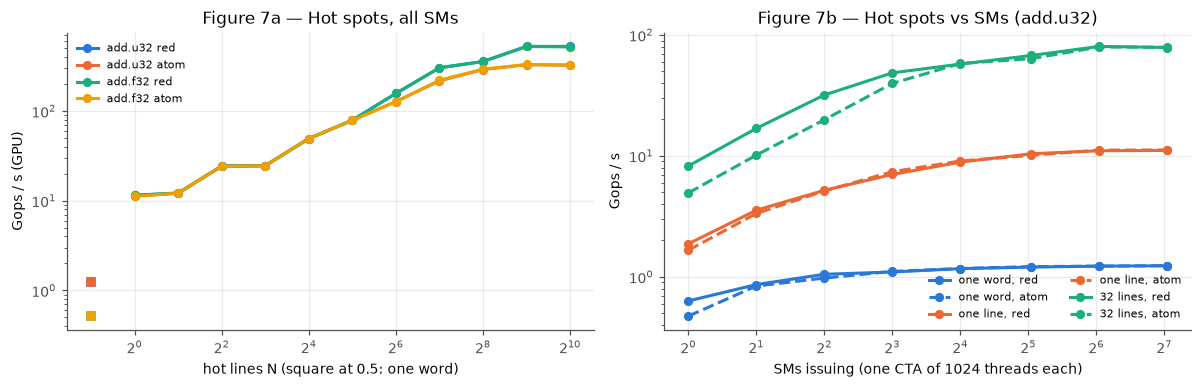

In [13]:
c = K3[K3.step == "k3c"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (op, kind) in enumerate([("add.u32", "red"), ("add.u32", "atom"), ("add.f32", "red"), ("add.f32", "atom")]):
    d = c[(c.op == op) & (c.kind == kind)]
    m = d[d.pattern == "hotN"].groupby("n_hot_lines").gops.median()
    one = d[d.pattern == "hot1"].gops.median()
    axs[0].plot(list(m.index), m.values, marker="o", color=C[i], label=f"{op} {kind}")
    axs[0].scatter([0.5], [one], marker="s", color=C[i])
axs[0].set_xscale("log", base=2)
axs[0].set_yscale("log")
axs[0].set_xlabel("hot lines N (square at 0.5: one word)")
axs[0].set_ylabel("Gops / s (GPU)")
axs[0].legend(fontsize=7)
axs[0].set_title("Figure 7a — Hot spots, all SMs")
s = K3[K3.step == "k3c_sms"]
for i, (pat, n, lab) in enumerate([("hot1", 0, "one word"), ("hotN", 1, "one line"), ("hotN", 32, "32 lines")]):
    for k, kind in enumerate(["red", "atom"]):
        m = s[(s.pattern == pat) & (s.n_hot_lines == n) & (s.op == "add.u32") & (s.kind == kind)].groupby("active_sms").gops.median()
        axs[1].plot(m.index, m.values, marker="o", ls="-" if kind == "red" else "--", color=C[i], label=f"{lab}, {kind}")
axs[1].set_xscale("log", base=2)
axs[1].set_yscale("log")
axs[1].set_xlabel("SMs issuing (one CTA of 1024 threads each)")
axs[1].set_ylabel("Gops / s")
axs[1].legend(fontsize=7, ncol=2)
axs[1].set_title("Figure 7b — Hot spots vs SMs (add.u32)")
plt.tight_layout()
plt.show()

In [14]:
NC = pd.read_csv("results/12__atomics__ncu.csv")
NC = NC[NC.run_id.isin(set(NC.run_id))]
NC["role"] = NC.config.str.extract(r"role=(\w+)")[0]
NC["label"] = NC.config.str.extract(r"label=([^;]+)")[0].fillna(NC.config.str.extract(r"kernel=(\w+);op=([^;]+);pattern=(\w+)").fillna("").agg("/".join, axis=1))
want = ["lts__t_requests_srcunit_tex_op_red.sum", "lts__t_requests_srcunit_tex_op_atom.sum", "lts__t_sectors_op_red.sum", "lts__t_sectors_op_atom.sum",
        "lts__t_sectors_op_red.max", "lts__t_sectors_op_atom.max", "lts__t_sectors_srcunit_ltcfabric.sum", "smsp__inst_executed_op_global_red.sum",
        "l1tex__t_requests_pipe_lsu_mem_global_op_atom.sum", "dram__bytes_read.sum"]
g = NC[NC.tag.str.startswith("tput") & NC.metric.isin(want)].copy()
g["value"] = pd.to_numeric(g.value, errors="coerce")
base = g[g.role == "baseline"].groupby(["tag", "metric"]).value.first()
prof = g[g.role == "profiled"].groupby(["tag", "metric"]).value.first()
net = (prof - base.reindex(prof.index).fillna(0)).unstack("metric")
labs = g[g.role == "profiled"].groupby("tag").label.first()
ops = NC[NC.role == "profiled"].config.str.extract(r"ops=(\d+)")[0].astype(float).groupby(NC[NC.role == "profiled"].tag).first()
net.insert(0, "ops issued", ops)
net.index = [labs[t] for t in net.index]
net = net[[c for c in ["ops issued"] + want if c in net.columns]]
display(Markdown("**Table 7 — Nsight Compute counters of profiled K2/K3 launches, minus a same-grid all-exit baseline** (`.max` = the busiest L2 slice; `.max == .sum` ⇔ one slice served everything)"))
with pd.option_context("display.float_format", "{:,.0f}".format):
    display(net.sort_index())

**Table 7 — Nsight Compute counters of profiled K2/K3 launches, minus a same-grid all-exit baseline** (`.max` = the busiest L2 slice; `.max == .sum` ⇔ one slice served everything)

metric,ops issued,lts__t_requests_srcunit_tex_op_red.sum,lts__t_requests_srcunit_tex_op_atom.sum,lts__t_sectors_op_red.sum,lts__t_sectors_op_atom.sum,lts__t_sectors_op_red.max,lts__t_sectors_op_atom.max,lts__t_sectors_srcunit_ltcfabric.sum,smsp__inst_executed_op_global_red.sum,l1tex__t_requests_pipe_lsu_mem_global_op_atom.sum,dram__bytes_read.sum
ncu_k3a/global/add.u32/atom/coal/local/t1024/i4/F16M/N1/mff,"69,206,016",0,2162952,0,8651148,0,92416,74072,0,2162952,-256
ncu_k3a/global/add.u32/atom/coal/mixed/t1024/i4/F256M/N1/mff,"69,206,016",0,2162952,0,12971404,0,138896,4353725,0,2162952,277100800
ncu_k3a/global/add.u32/atom/coal/remote/t1024/i4/F16M/N1/mff,"69,206,016",0,2162952,0,17301900,0,184832,8737662,0,2162952,-1280
ncu_k3a/global/add.u32/ld/coal/local/t1024/i4/F16M/N1/mff,"69,206,016",0,264,0,396,0,264,6294,0,264,512
ncu_k3a/global/add.u32/ld/coal/remote/t1024/i4/F16M/N1/mff,"69,206,016",0,264,0,396,0,264,48691,0,264,256
ncu_k3a/global/add.u32/red/coal/local/t1024/i4/F16M/N1/mff,"69,206,016",2162688,264,8650752,396,92152,264,71373,2162688,264,2816
ncu_k3a/global/add.u32/red/coal/mixed/t1024/i4/F256M/N1/mff,"69,206,016",2162688,264,12965120,396,138360,264,4359298,2162688,264,277079552
ncu_k3a/global/add.u32/red/coal/remote/t1024/i4/F16M/N1/mff,"69,206,016",2162688,264,17301504,396,184568,264,8698483,2162688,264,-1024
ncu_k3a/global/add.u32/st/coal/local/t1024/i4/F16M/N1/mff,"69,206,016",0,264,0,396,0,264,5817,0,264,512
ncu_k3a/global/add.u32/st/coal/remote/t1024/i4/F16M/N1/mff,"69,206,016",0,264,0,396,0,264,8689716,0,264,768


In [15]:
l2n = NC[NC.tag == "l2"].copy()
l2n["value"] = pd.to_numeric(l2n.value, errors="coerce")
l2n["order"] = l2n.config.str.extract(r"order=(\d+)")[0].astype(int)
l2n["what"] = l2n.config.str.extract(r"target=([^;]+);op=([^;]+);kind=([^;]+);pass=([^;]+)").agg(" ".join, axis=1)
pv = l2n.pivot_table(index=["order", "what"], columns="metric", values="value", aggfunc="first")
b0 = pv.iloc[0]
cols = [c for c in ["lts__t_sectors_srcunit_ltcfabric.sum", "lts__t_sectors_op_atom.sum", "lts__t_sectors_op_red.sum", "lts__t_sectors_op_read.sum",
                    "lts__t_sectors_op_write.sum", "lts__t_requests_srcunit_tex_op_atom.sum", "lts__t_sectors_srcunit_tex_lookup_miss.sum"] if c in pv.columns]
per = (pv[cols].iloc[1:] - b0[cols]) / 4096
display(Markdown("**Table 8 — Counters per operation of the 4096-hop L2 protocols** (SM 0; minus a 16-hop baseline launch; per hop)"))
display(per.round(2))

**Table 8 — Counters per operation of the 4096-hop L2 protocols** (SM 0; minus a 16-hop baseline launch; per hop)

,metric,lts__t_sectors_srcunit_ltcfabric.sum,lts__t_sectors_op_atom.sum,lts__t_sectors_op_red.sum,lts__t_sectors_op_read.sum,lts__t_sectors_op_write.sum,lts__t_requests_srcunit_tex_op_atom.sum,lts__t_sectors_srcunit_tex_lookup_miss.sum
order,what,,,,,,,
1,l2_near add.u32 atom 1,-0.3,1.0,0.0,3.0e-02,1.9e-01,1.0,0.0
2,l2_near add.u32 atom 2,-0.4,1.0,0.0,-1.1e-01,1.6e+00,1.0,-0.0
3,l2_near add.u32 ld 2ld,-0.4,0.0,0.0,1.2e+00,9.3e+00,0.0,-0.0
4,l2_near add.u32 red+ld 1,-0.3,0.0,1.0,1.0e+00,2.0e-02,0.0,0.0
5,l2_near add.u32 red+ld 2,-0.4,0.0,1.0,4.8e-01,2.3e+00,0.0,-0.0
6,l2_near add.u32 ld 2ld,-0.4,0.0,0.0,4.2e-01,2.0e-02,0.0,-0.0
7,l2_near cas.b32 atom 1,-0.3,1.0,0.0,9.5e-01,1.4e+00,1.0,0.0
8,l2_near cas.b32 atom 2,-0.4,1.0,0.0,-5.5e-01,2.6e-01,1.0,-0.0
9,l2_near cas.b32 ld 2ld,-0.4,0.0,0.0,4.1e-01,6.0e-02,0.0,-0.0


### 4.8 DSMEM: fire-and-forget throughput, contention, hand-off, store width

Figure 8a shows one CTA of 1024 threads issuing into a peer (cluster of 2), and the ring over every resident cluster (every rank into the next one). Figure 8b shows 1–15 CTAs of a 16-CTA cluster into one CTA, with that CTA idle or running its own atomics on the same words. Figure 8c shows the round trip of a hand-off per signalling primitive over all 120 pairs of GPC 1. Figure 8d shows the store width.

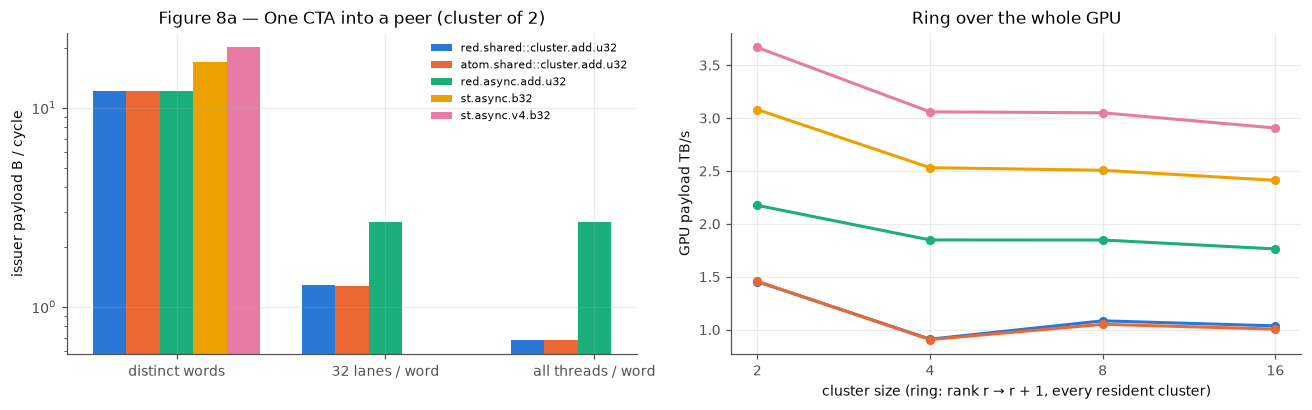

**Table 9 — One CTA into a peer**: issue span (red / atom: until every thread's fence returned) and completion at the receiver (`.async`: last mbarrier phase)

cycles      ops  completion_cycles  issue_ops_per_cycle  completion_ops_per_cycle
op                           pattern                                                                                     
atom.shared::cluster.add.u32 distinct  1.4e+06  4.2e+06                NaN                  3.0                       NaN
                             one       2.5e+07  4.2e+06                NaN                  0.2                       NaN
                             per32     1.3e+07  4.2e+06                NaN                  0.3                       NaN
red.async.add.u32            distinct  1.4e+06  4.2e+06            1.4e+06                  3.0                       3.0
                             one       6.3e+06  4.2e+06            6.3e+06                  0.7                       0.7
                             per32     6.3e+06  4.2e+06            6.3e+06                  0.7                       0.7
red.shared::cluster.add.u32  distinct  1.4e+06  4.2e+06                NaN                  3.0                       NaN
                             one       2.5e+07  4.2e+06                NaN                  0.2                       NaN
                             per32     1.3e+07  4.2e+06                NaN                  0.3                       NaN
st.async.b32                 distinct  9.9e+05  4.2e+06            9.9e+05                  4.2                       4.2
st.async.v4.b32              distinct  3.3e+06  4.2e+06            3.3e+06                  1.3                       1.3

In [16]:
K45 = read_ids("12__dsmem_atomics__throughput.csv", [SRC["k4"], SRC["k4ring"], SRC["k5"]])
k4 = K45[K45.kernel == "k4"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ops4 = ["red.shared::cluster.add.u32", "atom.shared::cluster.add.u32", "red.async.add.u32", "st.async.b32", "st.async.v4.b32"]
x = np.arange(3)
for i, op in enumerate(ops4):
    src_ = k4[(k4.op == op) & (k4.role == "src")].groupby("pattern").bpc.median()
    dst = k4[(k4.op == op) & (k4.role == "dst")]
    vals = [src_.get(p, np.nan) for p in ["distinct", "per32", "one"]]
    axs[0].bar(x + (i - 2) * 0.16, vals, 0.16, color=C[i], label=op)
axs[0].set_xticks(x, ["distinct words", "32 lanes / word", "all threads / word"])
axs[0].set_ylabel("issuer payload B / cycle")
axs[0].set_yscale("log")
axs[0].legend(fontsize=7)
axs[0].set_title("Figure 8a — One CTA into a peer (cluster of 2)")
r = K45[(K45.kernel == "k4ring") & (K45.role == "src")]
for i, op in enumerate(ops4):
    m = r[r.op == op].groupby(["cs", "launch_idx"]).agg(ops=("ops", "sum"), ms=("ms_event", "first")).reset_index()
    m["gops"] = m.ops / ((m.ms - EVENT_FLOOR_MS) * 1e-3) / 1e9
    mm = m.groupby("cs").gops.median()
    axs[1].plot(mm.index, mm.values * (16 if "v4" in op else 4) / 1e3, marker="o", color=C[i], label=op)
axs[1].set_xscale("log", base=2)
axs[1].set_xticks([2, 4, 8, 16], ["2", "4", "8", "16"])
axs[1].set_xlabel("cluster size (ring: rank r → r + 1, every resident cluster)")
axs[1].set_ylabel("GPU payload TB/s")
axs[1].set_title("Ring over the whole GPU")
plt.tight_layout()
plt.show()
comp = k4[(k4.role == "dst") & k4.completion_cycles.notna()].groupby(["op", "pattern"]).completion_cycles.median()
iss = k4[(k4.role == "src")].groupby(["op", "pattern"]).agg(cycles=("cycles", "median"), ops=("ops", "median"))
t8 = iss.join(comp).assign(issue_ops_per_cycle=lambda d: d.ops / d.cycles, completion_ops_per_cycle=lambda d: d.ops / d.completion_cycles)
display(Markdown("**Table 9 — One CTA into a peer**: issue span (red / atom: until every thread's fence returned) and completion at the receiver (`.async`: last mbarrier phase)"))
display(t8.round(3))

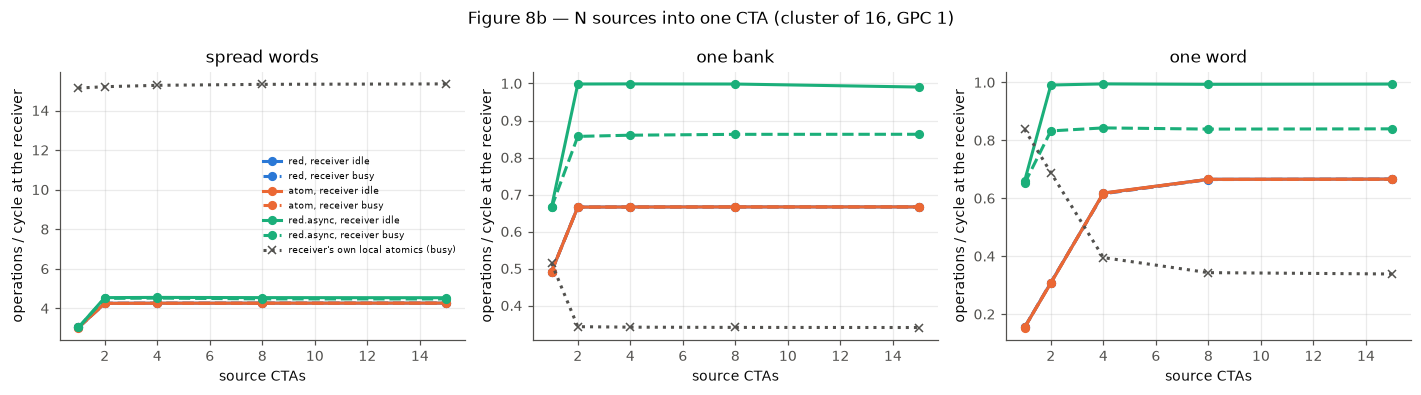

In [17]:
k5 = K45[K45.kernel == "k5"]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for j, pat in enumerate(["distinct", "same_bank", "one"]):
    ax = axs[j]
    for i, op in enumerate(["red.shared::cluster.add.u32", "atom.shared::cluster.add.u32", "red.async.add.u32"]):
        for busy in [0, 1]:
            m = k5[(k5.op == op) & (k5.pattern == pat) & (k5.role == "dst") & (k5.dest_busy == busy)].groupby("n_sources").ops_per_cycle.median()
            ax.plot(m.index, m.values, marker="o", ls="-" if busy == 0 else "--", color=C[i], label=f"{op.split('.')[0]}{'.async' if 'async' in op else ''}, receiver {'busy' if busy else 'idle'}")
    loc = k5[(k5.role == "dst_local") & (k5.pattern == pat)].groupby("n_sources").ops_per_cycle.median()
    ax.plot(loc.index, loc.values, color=INK2, ls=":", marker="x", label="receiver's own local atomics (busy)")
    ax.set_xlabel("source CTAs")
    ax.set_ylabel("operations / cycle at the receiver")
    ax.set_title({"distinct": "spread words", "same_bank": "one bank", "one": "one word"}[pat])
axs[0].legend(fontsize=6)
fig.suptitle("Figure 8b — N sources into one CTA (cluster of 16, GPC 1)")
plt.tight_layout()
plt.show()

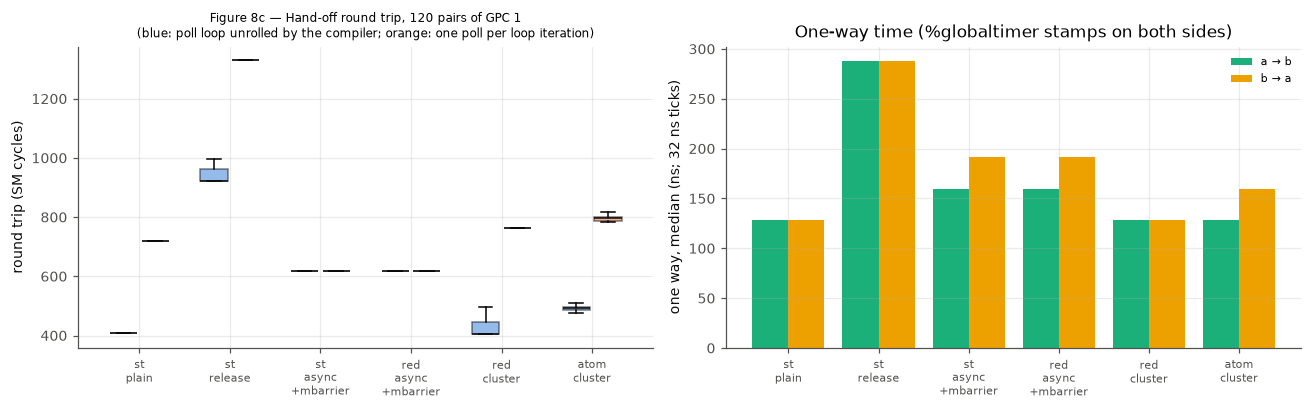

**Table 10 — DSMEM hand-off per primitive** (round trip without timer reads in the loop; one way from the `gt` variant)

rt_median   rt_p5  rt_p95  one_way_ns       n
primitive          variant                                                  
atom_cluster       gt                NaN     NaN     NaN       128.0  120000
                   gt_poll1          NaN     NaN     NaN       224.0  120000
                   nogt            492.0   482.0   503.0         NaN  240000
                   nogt_poll1      796.0   620.0   808.0         NaN  240000
red_async_mbarrier gt                NaN     NaN     NaN       160.0  120000
                   gt_poll1          NaN     NaN     NaN       160.0  120000
                   nogt            619.0   429.0   619.0         NaN  240000
                   nogt_poll1      619.0   429.0   619.0         NaN  240000
red_cluster        gt                NaN     NaN     NaN       128.0  120000
                   gt_poll1          NaN     NaN     NaN       224.0  120000
                   nogt            406.0   404.0   445.0         NaN  240000
                   nogt_poll1      763.0   763.0   937.0         NaN  240000
st_async_mbarrier  gt                NaN     NaN     NaN       160.0  120000
                   gt_poll1          NaN     NaN     NaN       160.0  120000
                   nogt            619.0   429.0   619.0         NaN  240000
                   nogt_poll1      619.0   429.0   619.0         NaN  240000
st_plain           gt                NaN     NaN     NaN       128.0  120000
                   gt_poll1          NaN     NaN     NaN       224.0  120000
                   nogt            410.0   369.0   412.0         NaN  240000
                   nogt_poll1      721.0   721.0   893.0         NaN  240000
st_release         gt                NaN     NaN     NaN       288.0  120000
                   gt_poll1          NaN     NaN     NaN       384.0  120000
                   nogt            923.0   921.0   962.0         NaN  240000
                   nogt_poll1     1330.0  1158.0  1330.0         NaN  240000

**Table 11 — Global-flag hand-off** (two pinned warps; flag lines homed as stated; round trip median, one way median)

round_trip_cycles                                               one_way_ns                                   
primitive                                atom.acq_rel.gpu.exch red.release.gpu.add st.release.gpu atom.acq_rel.gpu.exch red.release.gpu.add st.release.gpu
pair                  homes                                                                                                                               
0–10 (same partition) home_far_both                     2494.0              2355.0         2173.0                 736.0               736.0          640.0
                      home_near_both                    1714.0              1736.0         1736.0                 512.0               512.0          512.0
0–2 (other partition) home_near_consumer                2247.0              2196.0         2184.0                 640.0               672.0          672.0
                      home_near_producer                2321.0              2484.0         2484.0                 736.0               768.0          768.0

In [18]:
V = read_ids("12__dsmem_atomics__visibility.csv", [SRC[m] for m in ["k6", "k6poll1", "flags"] if m in SRC])
vd = V[V.scope == "cluster"]
prims = ["st_plain", "st_release", "st_async_mbarrier", "red_async_mbarrier", "red_cluster", "atom_cluster"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for k, var in enumerate(["nogt", "nogt_poll1"]):
    d = vd[vd.variant == var]
    if d.empty:
        continue
    data = [d[d.primitive == p].round_trip_cycles.dropna().values for p in prims]
    axs[0].boxplot(data, positions=np.arange(len(prims)) + (k - 0.5) * 0.35, widths=0.3, showfliers=False,
                   patch_artist=True, boxprops=dict(facecolor=C[k], alpha=0.5), medianprops=dict(color=INK))
axs[0].set_xticks(np.arange(len(prims)), [p.replace("_mbarrier", "\n+mbarrier").replace("_", "\n", 1) for p in prims], fontsize=7)
axs[0].set_ylabel("round trip (SM cycles)")
axs[0].set_title("Figure 8c — Hand-off round trip, 120 pairs of GPC 1\n(blue: poll loop unrolled by the compiler; orange: one poll per loop iteration)", fontsize=8)
d = vd[vd.variant == "gt"]
ow = d.groupby("primitive").one_way_ns.median().reindex(prims)
owb = d.groupby("primitive").one_way_back_ns.median().reindex(prims)
axs[1].bar(np.arange(len(prims)) - 0.2, ow.values, 0.4, color=C[2], label="a → b")
axs[1].bar(np.arange(len(prims)) + 0.2, owb.values, 0.4, color=C[3], label="b → a")
axs[1].set_xticks(np.arange(len(prims)), [p.replace("_mbarrier", "\n+mbarrier").replace("_", "\n", 1) for p in prims], fontsize=7)
axs[1].set_ylabel("one way, median (ns; 32 ns ticks)")
axs[1].legend(fontsize=7)
axs[1].set_title("One-way time (%globaltimer stamps on both sides)")
plt.tight_layout()
plt.show()
t = vd.groupby(["primitive", "variant"]).agg(rt_median=("round_trip_cycles", "median"), rt_p5=("round_trip_cycles", lambda s: s.quantile(.05)),
                                             rt_p95=("round_trip_cycles", lambda s: s.quantile(.95)), one_way_ns=("one_way_ns", "median"),
                                             n=("trial", "size"))
display(Markdown("**Table 10 — DSMEM hand-off per primitive** (round trip without timer reads in the loop; one way from the `gt` variant)"))
display(t.round(1))
vg = V[V.scope == "gpu"]
part = PART.set_index("smid").partition
vg = vg.assign(pair=vg.smid_src.astype(str) + "–" + vg.smid_dst.astype(str) +
               np.where(vg.smid_src.map(part) == vg.smid_dst.map(part), " (same partition)", " (other partition)"))
tg = vg.groupby(["pair", "variant", "primitive"]).agg(rt=("round_trip_cycles", "median"), ow=("one_way_ns", "median")).reset_index()
tg["homes"] = tg.variant.str.replace("_gt", "")
tg = tg.groupby(["pair", "homes", "primitive"]).agg(round_trip_cycles=("rt", "max"), one_way_ns=("ow", "max")).unstack("primitive")
display(Markdown("**Table 11 — Global-flag hand-off** (two pinned warps; flag lines homed as stated; round trip median, one way median)"))
display(tg.round(0))

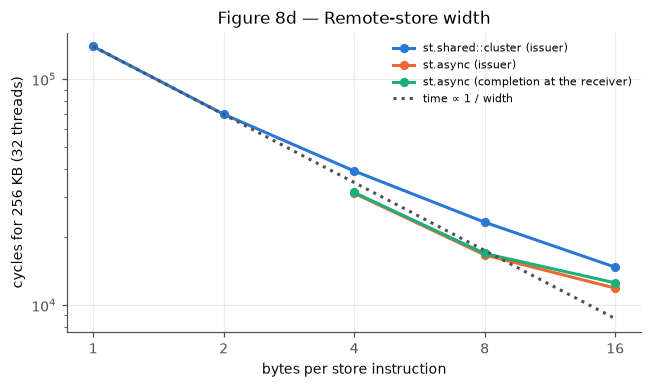

width    cycles   bpc
primitive                 side                         
st.shared::cluster.u8     issuer      1  139598.0   1.9
st.shared::cluster.u16    issuer      2   69970.0   3.8
st.async.b32              dest        4   31531.0   8.3
                          issuer      4   31276.0   8.4
st.shared::cluster.u32    issuer      4   39244.0   6.7
st.async.v2.b32           dest        8   16184.0  16.2
st.async.b64              dest        8   17669.0  14.8
                          issuer      8   17448.0  15.0
st.shared::cluster.v2.u32 issuer      8   23401.0  11.2
st.shared::cluster.u64    issuer      8   23144.0  11.3
st.async.v2.b32           issuer      8   15916.0  16.5
st.async.v4.b32           dest       16   12553.0  20.9
                          issuer     16   11895.0  22.0
st.shared::cluster.v4.u32 issuer     16   14724.5  17.8

In [19]:
W = read_ids("12__dsmem_atomics__width.csv", [SRC["k7"]])
fig, ax = plt.subplots(figsize=(6, 3.6))
for i, (fam, side) in enumerate([("st.shared::cluster", "issuer"), ("st.async", "issuer"), ("st.async", "dest")]):
    d = W[W.primitive.str.startswith(fam) & (W.side == side)].groupby("width_bytes").cycles.median()
    ax.plot(d.index, d.values, marker="o", color=C[i], label=f"{fam} ({'completion at the receiver' if side == 'dest' else 'issuer'})")
x = np.array([1, 16])
ax.plot(x, W[(W.primitive == "st.shared::cluster.u8")].cycles.median() / x, ls=":", color=INK2, label="time ∝ 1 / width")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks([1, 2, 4, 8, 16], ["1", "2", "4", "8", "16"])
ax.set_xlabel("bytes per store instruction")
ax.set_ylabel("cycles for 256 KB (32 threads)")
ax.legend(fontsize=7)
ax.set_title("Figure 8d — Remote-store width")
plt.tight_layout()
plt.show()
display(W.groupby(["primitive", "side"]).agg(width=("width_bytes", "first"), cycles=("cycles", "median"), bpc=("bpc", "median")).sort_values("width").round(2))

In [20]:
display(Markdown("**Summary table** (default semantics; latency = Table 1; per SM = K2 best ILP at 1024 threads, coalesced; GPU = K3 at 16 MiB (L2) / 256 MiB (HBM))"))
main = ["add.u32", "cas.b32", "exch.b32", "add.u64", "add.f32", "add.f16x2"]
sm_ = SUMM[SUMM.op.isin(main) & SUMM.kind.isin(["atom", "red+ld"])]
display(sm_[["target", "cs", "op", "kind", "latency_cycles", "ld_ref_cycles", "sm_ops_per_cycle", "sm_bpc", "gpu_gops", "gpu_tbps_payload"]]
        .set_index(["target", "cs", "op", "kind"]).round(2))

**Summary table** (default semantics; latency = Table 1; per SM = K2 best ILP at 1024 threads, coalesced; GPU = K3 at 16 MiB (L2) / 256 MiB (HBM))

latency_cycles  ld_ref_cycles  sm_ops_per_cycle  sm_bpc  gpu_gops  gpu_tbps_payload
target        cs op        kind                                                                                       
smem          1  add.f16x2 atom             113.3           44.3               6.8    27.3       NaN               NaN
                           red+ld           137.8           44.3               7.1    28.2       NaN               NaN
                 add.f32   atom             100.1           28.9               6.8    27.2       NaN               NaN
                           red+ld           121.7           28.9               7.1    28.3       NaN               NaN
                 add.u32   atom              32.3           28.9              13.5    54.1       NaN               NaN
                           red+ld            33.4           28.9              15.9    63.7       NaN               NaN
                 add.u64   atom             121.6            NaN               5.1    40.5       NaN               NaN
                           red+ld           143.3            NaN               5.3    42.1       NaN               NaN
                 cas.b32   atom              36.5           28.9              12.7    50.8       NaN               NaN
                 exch.b32  atom              31.8           28.9               NaN     NaN       NaN               NaN
smem_dsmem_if 2  add.f16x2 atom             228.7           53.5               3.7    14.6       NaN               NaN
                           red+ld           246.1           53.5               4.0    16.0       NaN               NaN
                 add.f32   atom             212.5           37.2               3.6    14.6       NaN               NaN
                           red+ld           226.4           37.2               4.0    16.1       NaN               NaN
                 add.u32   atom              41.5           37.2              10.6    42.4       NaN               NaN
                           red+ld            48.0           37.2              11.6    46.4       NaN               NaN
                 add.u64   atom              88.9            NaN               7.4    58.9       NaN               NaN
                           red+ld           113.4            NaN               8.0    63.7       NaN               NaN
                 cas.b32   atom              45.4           37.2              10.0    40.2       NaN               NaN
                 exch.b32  atom              41.4           37.2               NaN     NaN       NaN               NaN
dsmem         2  add.f16x2 atom             310.1          209.0               2.7    10.8       NaN               NaN
                           red+ld           490.1          209.0               2.7    10.9       NaN               NaN
                 add.f32   atom             562.4          192.4               1.4     5.5       NaN               NaN
                           red+ld           726.3          192.4               1.4     5.6       NaN               NaN
                 add.u32   atom             200.4          192.4               3.0    12.2       NaN               NaN
                           red+ld           205.9          192.4               3.0    12.2       NaN               NaN
                 add.u64   atom             215.3            NaN               1.8    14.2       NaN               NaN
                           red+ld           282.9            NaN               1.8    14.2       NaN               NaN
                 cas.b32   atom             202.4          192.4               1.6     6.6       NaN               NaN
                 exch.b32  atom             200.4          192.4               NaN     NaN       NaN               NaN
              4  add.f16x2 atom             334.1          232.0               2.7    10.8       NaN               NaN
                           red+ld           536.1          232.0               2.7    10.9       NaN        

## 5. Insights

**1. An integer atomic costs a fixed, small amount more than a load on every path.** All values are SM cycles at 1635 MHz, from dependent chains (Table 1).

| path | plain load | add.u32 atom | atomic − load |
|---|---|---|---|
| local shared memory | 28.9 | 32.3 | +3.4 |
| own smem through the cluster window | 37.2 | 41.5 | +4.3 |
| peer CTA (DSMEM) | 186–222 by SM pair | load + 8.00 | +8.00 on every one of ≈ 1800 SM pairs (spread 0.003) |
| L2, line homed near | 272.8 | 284 | +11 |
| L2, line homed far | 434 (first read) | 461 | +27 |
| HBM miss, near / far home | 522 / 684 | 538 / 695 | +16 / +11 |
| host memory | 1585 | ≈ 1670 | +85 |

- **Same cost for every single-instruction integer op.** `inc`, `min`, `max` and `and` cost the same as `add`; `exch` costs the same or slightly less (at an HBM miss it costs the same as a load). A `cas` that fails costs +2…+4 more than `add`; a succeeding `cas` on one word costs +9…+16 more.
- **64-bit and vector forms.** Atomics on 64-bit words add 14–25 cycles in L2. The vector global forms (`.v2/.v4.f32`, `.v2/.v4.f16x2`) add 20–30 cycles in L2 and 50–60 at an HBM miss.
- **`red` + load.** Reading back one's own `red` takes 1–6 cycles longer than `atom` in shared memory, 7 longer in near L2 and 20 longer far. Behind a far `red` the load also goes far: the `red` removes the reader's copy of the line.
- **DSMEM model.** The remote atomic is the remote load plus a constant 8 cycles; the cost is not set by the distance. A peer atomic is therefore the same per-SM-pair network round trip as a load plus 8 cycles in the owner SM's atomic unit.

**2. Global atomics always execute at the line's home L2 partition.**
- A line homed in the other partition is far on the first atomic (461 cycles) and stays far on every later one (pass 2: 461). A load becomes near after its first access (434 → 279).
- The atomics leave no copy in the issuer's partition: a plain load after the atomic passes is still far (434).
- The counters agree (Table 8). A far atomic is looked up in both partitions (2 L2 atomic sectors per operation instead of 1) and moves ≈ 1 sector over the partition link; a near atomic is one lookup and no link traffic.
- **GPU-wide consequence.** At 16 MiB, remote-homed lines (each partition's SMs on the other partition's lines) run at 1.8 TB/s for `red` and 1.0 TB/s for `atom`, against 3.2 TB/s for both on local lines. With only one partition's GPCs issuing, remote atomics saturate at ≈ 0.88 TB/s of payload, against ≈ 1.1 TB/s for remote stores (Figure 6). On remote lines `atom` reaches only half of `red`'s rate; `red` behaves like a store.
- **On a random buffer**, half the lines are remote, which explains why `atom` "mixed" (1.9 TB/s) is far below `atom` local (3.2 TB/s) while `red` mixed stays at 3.2.

**3. Where floating-point and 64-bit atomics are slow is decided by the compiler, per state space** (Table 3b):
- **Local shared memory.** Only 32-bit integer ops, `exch` and `cas` are native `ATOMS`. `add.f32`/`.f64`/`.u64`/`.f16x2`/`.bf16x2` become compare-and-swap loops: 100–122 cycles instead of 32, and 5–7 instead of 13.5 operations per cycle per SM.
- **Peer CTA (DSMEM).** `add.u64` and the 16-bit-pair adds are native `ATOM.E` (+23 and +101 cycles over the load). `add.f32`/`.f64` run a CAS loop over the network: 562 / 590 cycles, about 2.8 round trips, and 1.4 operations per cycle per SM.
- **Global memory.** Every op is a native `ATOMG`/`REDG`, including the vector f32/f16x2 forms.

  So the fast place for a floating-point atomic reduction on this GPU is the L2, not shared memory. In shared memory, the only fast reduction is a 32-bit integer one.

**4. Memory-ordering semantics cost a fence, not a different atomic.**
- `.relaxed` at any scope costs the same as the default.
- `.acq_rel.cta` adds 5–9 cycles.
- `.acq_rel.cluster` and `.acq_rel.gpu` are identical on every path: they add a GPU-scope memory barrier and an L1 invalidate. That costs +261 cycles on shared memory, +392 near and +531 far in L2, and +460 on host memory.
- `.sys` costs ≈ 1280 cycles in shared memory and ≈ 1370 / 1550 in near / far L2.
- A `.cluster` scope therefore gives no saving over `.gpu` on this GPU.

**5. One SM's atomic throughput, and where contention serialises** (Table 4, Figure 4):
- **Local shared memory.** A conflict-free `atom.add.u32` reaches 13.5 operations per cycle (54 B/cycle), against 14.9 for a plain 4-B load. Any two lanes on the same bank cost one cycle each: same-bank, same-word-per-warp and same-word-per-CTA patterns all run at exactly 1.0 operation per cycle.
- **Compiler exception.** `red.shared.add.u32` with the constant operand 1 (`atomicAdd(&x, 1)` without using the result) is compiled to `ATOMS.POPC.INC`. It adds the number of lanes that hit the same word in one operation, so a CTA counting into one word reaches 15.9 operations per cycle. With a non-constant operand the same reduction runs at 1.0.
- **Through the window, own CTA.** 10.6 operations per cycle; contention patterns again 1.0.
- **Into a peer CTA.** `red` and `atom` are capped at 3.05 operations per cycle per sender (12 B/cycle), below the 4.27 of 4-B remote loads or stores of the same addresses. The cap is the operation rate, not bytes.
  - A peer word hit by every lane of a warp runs at 0.33 operations per cycle; one word for the whole CTA at 0.17 (≈ 6 cycles per operation at the owner).
  - With one CTA per SM on every SM, the per-SM rates fall to 1.7 (coalesced) and 0.13 (one word).
- **L2 and HBM, one SM.** `red` ≈ 5.9 operations per cycle (≈ 24 B/cycle), the same as a plain store, for near and far lines alike. `atom` reaches 5.5 at 4–8 operations in flight per thread. 64-bit operations run at 3.2 per cycle (25.6 B/cycle).
- **L2 and HBM, every SM at once.** The per-SM share drops to 4.2 (near), 2.2 (far: the partition link) and 1.6 (HBM).
- **Contended global words.** One word per warp instruction, or per CTA, runs at 0.5 (`atom`) / 0.8–0.95 (`red`) operations per cycle from one SM, i.e. one L2 request per lane.

**6. Hot spots in the L2 are served by one slice, one request per lane, without merging** (Table 7, Figure 7).
- Every thread of the GPU on one word reaches 1.2 Gops/s for `add.u32`. That is ≈ 0.8 operations per L2 cycle; four SMs already reach 80 % of it. `add.f32` reaches only 0.52 Gops/s.
- The counters show one L2 request per thread, not per warp instruction. The busiest slice equals the total (`.max == .sum`), and the memory sums match the issued operations: same-address operations are neither merged in the SM nor in the L2; they are serialised in one slice.
- One hot line (each warp instruction one full line of 32 words) runs at 11 Gops/s, 9× one word. Throughput then grows linearly with the number of hot lines up to ≈ 256–512 lines, where it saturates at ≈ 330 Gops/s (`atom`) and ≈ 525 Gops/s (`red`), the throughput of the whole L2 for these patterns.
- Beyond the L2 capacity (≥ 96 MiB), atomics drop to ≈ 1.2–1.4 TB/s of payload, against 2.0–2.9 TB/s for plain loads and stores of the same lines.

**7. DSMEM fire-and-forget forms.**
- **Sending.** `red.async` sends at the same 3.0 operations per cycle as `red` and `atom`. `st.async` sends at 4.2 (`.b32`) and 1.25 (`.v4`: 20 B/cycle) operations per cycle, the highest rate any DSMEM store form reached here.
- **Completion.** For every `.async` form, the receiver's mbarrier completes at the same time as the sender finishes issuing: the mbarrier accounting costs no throughput.
- **Same-word reductions.** `red.async` runs 4× faster than `red`/`atom` on one word (0.66 vs 0.17 operations per cycle). Up to 15 senders into one CTA saturate the receiver at ≈ 4.3–4.5 operations per cycle for spread words, 0.67 (`red`/`atom`) or 1.0 (`red.async`) on one bank or one word.
- **A busy receiver.** A receiver running its own atomics on the same words keeps 15 local operations per cycle on spread words, but drops to 0.34 on one bank or one word, while the remote rate stays at its 0.67 limit.
- **GPU-wide ring.** Every cluster, every rank into the next: 3.7 / 3.1 / 2.2 / 1.45 TB/s for `st.async.v4` / `st.async.b32` / `red.async` / `red` at clusters of 2, and 2.9 / 2.4 / 1.8 / 1.0 at clusters of 16.

**8. Hand-off between two SMs** (Figure 8c, Tables 10–11).
- Within a GPC every SM pair gives the same round trip.
- **Primitive ranking**, with the compiler's unrolled poll loop:
  - plain remote store or remote `red` on a flag: 406–410 cycles (one way ≈ 128 ns);
  - remote `atom` whose return is used: 492;
  - `st.async` / `red.async` + mbarrier: 619 (160 ns);
  - `st.release.cluster`: 923 (288 ns), because of the fence.
- **The poll loop's code moves the flag hand-offs.** With one poll and one scheduler yield per loop iteration, the same flag hand-offs take 721–796 cycles. The mbarrier hand-offs stay at 619, because the wait instruction itself sets their granularity. Absolute flag hand-off times thus depend on how the waiting loop is compiled, by up to ≈ 300 cycles; the mbarrier forms do not. All round trips are multimodal, with steps of 40–190 cycles.
- **Through global flags,** a hand-off takes 1714–1736 cycles when both flag lines are homed in the pair's own partition. It takes 2184–2484 cycles when a flag line, or one of the two SMs, is in the other partition. `red.release` and `atom.acq_rel` cost no less than `st.release`.

**9. Store width.** A remote plain store's issue cost per instruction is constant from 1 to 4 B (time halves per width doubling: 1.9 → 3.8 → 6.7 B/cycle for 32 threads). Above that, wider stores give diminishing returns: 11.3 B/cycle at 8 B, 17.8 at 16 B. `st.async` issues faster than plain stores at every width (8.4 / 15 / 16.5 / 22 B/cycle for 4 / 8 / 8 (v2) / 16 B), and its completion at the receiver follows the issue within 1–5 %.

**Anomalies and limitations.**
- **Clock during heavy L2 kernels.** In-kernel cycles per ns show SM clocks down to ≈ 1510–1570 MHz during the heaviest GPU-wide L2 kernels, although NVML sampled 1635 MHz after them. Per-SM numbers are in SM cycles and unaffected; GPU-wide rates are wall-clock.
- **Discarded launches.** 18 launches of the 132-SM single-word-per-warp far-line `red` configuration were discarded and repeated after a software power-cap event (clock 1380–1620 MHz).
- **HBM tail.** The HBM per-access samples have k-means classes at ≈ 523 / 550 / 701 / 852 (near) and 675 / 711 / 863 / 1014 (far); a slow tail ≈ 150 cycles above each main class.
- **Encoding cost in absolute latencies.** Every chain hop includes the address arithmetic of one multiply-add (the f16x2/bf16x2 encoding ≈ 15 cycles more). It is the same in the plain-load reference, so differences to the load are exact, but absolute values include it.
- **Partition labels** were measured on this card (section 3), not assumed; every near / far result rests on them.